# Music Structure Analysis Notebook

Imports:

In [1]:
import numpy as np
import scipy 
import matplotlib.pyplot as plt
import IPython.display as ipd
import mir_eval

scipy.inf = np.inf  # the hack
import msaf
import seaborn as sns
sns.set(style="dark")

# Core MIR libraries
import librosa
import jams
import libfmp.b
import libfmp.c4



## ***Part 1: JAMS Structural Annotations (15 Marks)***

In this section I will take 3 previously created JAMS files and perform ground truth analysis on each one. The three recordings I have chosen are...

* What's Going On (Studio Recording)
* What's Going On (Live)
* If I Only Had a Soul (AI Generated Track)

I selected What’s Going On because Marvin Gaye was known for improvising during live performances, often extending sections, adding spoken monologues, and altering transitions. This makes the live version structurally different from the studio version, providing a meaningful comparison for segmentation analysis.


### **1. Annotation**

For annotation I have chosen to use segment_salami_upper namespace over segment_open as the prior uses consistent labels (A, B, C) which will make structural comparrisons between the live and studio version easier.


In [2]:
ori = jams.load("sglselwo_1_ori.jams")  ##  What's Going On (Studio)

ann = jams.Annotation(namespace="segment_salami_upper")  ##  New annotation

ori_segments = [
    (0.0, 7.5, "A"),      ##  Crowd Noise
    (7.5, 18.0, "B"),     ##  Intro
    (18.0, 37.0, "C"),    ##  Verse
    (37.0, 46.3, "D"),    ##  Prechorus p1
    (46.3, 65.7, "C"),    ##  Verse
    (65.7, 74.9, "D"),    ##  Prechorus p1
    (74.9, 88.9, "E"),    ##  Prechorus p2
    (88.9, 98.9, "F"),    ##  Chorus
    (98.9, 126.7, "G"),   ##  Postchorus
    (126.7, 145.9, "C"),  ##  Verse
    (145.9, 155.3, "D"),  ##  Prechorus p1
    (155.3, 169.0, "E"),  ##  Prechorus p2
    (169.0, 179.0, "F"),  ##  Chorus
    (179.0, 207.1, "G"),  ##  Postchorus
    (207.1, 232.0, "H")   ##  Outro
]

##  Cycle through and create each segment annotation individually
for start, end, label in ori_segments:
    ann.append(time=start, duration=end-start, value=label)

##  add annotation to jam file
ori.annotations.append(ann)


##  ori.save("./sglselwo_1_ori.jams")


In the snippet above, 
* Loaded the JAMS file
* Initialised a segment_salami_upper annotation name space
* One by one assigned each of my analysed segments into the annotation with the start and end times
* Appended the annotation to my jam file
* Update the jams file

I will now do this for the other two recordings

In [3]:
liv = jams.load("sglselwo_1_liv.jams")  ##  What's Going On (Live)

ann = jams.Annotation(namespace="segment_salami_upper")  ##  New annotation

liv_segments = [
    (0, 28.3, "A"),        ##  Crowd Noise
    (28.3, 40.9, "B"),     ##  Intro
    (40.9, 61.3, "C"),     ##  Verse
    (61.3, 72.6, "D"),     ##  Prechorus p1
    (72.6, 92.5, "C"),     ##  Verse
    (92.5, 102.9, "D"),    ##  Prechorus p1
    (102.9, 118.6, "E"),   ##  Prechorus p2 
    (118.6,  129.1, "F"),  ##  Chorus
    (129.1,  160.0, "G"),  ##  Postchorus
    (160.0,  180.2, "C"),  ##  Verse
    (180.2,  190.4, "D"),  ##  Prechorus p1
    (190.4,  205.8 , "E"), ##  Prechorus p2
    (205.8, 215.9, "F"),   ##  Chorus
    (215.9, 246.5, "G"),   ##  Postchorus
    (246.5, 335.1, "H"),   ##  Outro
    (335.1, 342, "A"),     ##  Crowd Noise
   
]

##  Cycle through and create each segment annotation individually
for start, end, label in liv_segments:
    ann.append(time=start, duration=end-start, value=label)

##  add annotation to jam file
liv.annotations.append(ann)


##  liv.save("./sglselwo_1_liv.jams")


In [4]:
gen = jams.load("sglselwo_3_gen.jams")  ##  If I Only Had A Soul (AI liverated)

ann = jams.Annotation(namespace="segment_salami_upper")  ##  New annotation

gen_segments = [
    (0.0, 23.5, "A"),  ##  Intro
    (23.5, 38.8, "B"),  ##  Verse
    (38.8, 54.5, "B"),  ##  Verse
    (54.5, 77.8 , "C"),  ##  Prechorus
    (77.8, 93.3, "D"),  ##  Chorus
    (93.3, 108.6, "E"), ##  Postchorus
    (108.6, 124.1, "B"),  ##  Verse
    (124.1, 140.1, "B"),  ##  Verse
    (140.1, 155.0, "D"),  ##  Chorus
    (155.0, 170.6, "D"),  ##  Chorus
    (170.6, 186.0, "F"),  ##  Bridge
    (186.0, 202.0, "D"),  ##  Chorus
    (202.0, 217.1, "D"),  ##  Chorus
    (217.1, 234.0, "G"),  ##  Outro
    (234.0, 237.8, "silence")  ##  silence

]

##  Cycle through and create each segment annotation individually
for start, end, label in gen_segments:
    ann.append(time=start, duration=end-start, value=label)

##  add annotation to jam file
gen.annotations.append(ann)


##  gen.save("./sglselwo_3_gen.jams")


PS. Notice how I do not save the files, this is because the assignment requires the files to already be there on submission, the code above simply shows how the annotated files were modified/created.

### **2. Validation**

Now that I have added the manual ground truth annotations, I will check the validity of the new JAMS files.

To do this I will load the newly annotated JAMS files with <span style="color: green;">strict=True</span>. If this causes error, we will know that the JAMS files are not valid.



In [5]:
ori_jam = jams.load("sglselwo_1_ori.jams", strict=True)
liv_jam = jams.load("sglselwo_1_liv.jams", strict=True)
gen_jam = jams.load("sglselwo_3_gen.jams", strict=True)

Hurray!!! No errors, this means I can move onto visualisation

### **3. Visualisation**



In [6]:
def getSegmentAnnotationInfo(jam):
    ann = jam.annotations["segment_salami_upper"][0]   ##  Loads segment annotation 
    starts = [obs.time for obs in ann]
    ends   = [obs.time + obs.duration for obs in ann]
    labels = [obs.value for obs in ann]
    return starts, ends, labels


def visualiseSegments(jam, title):
     
    ##  Gathers segment annotations
    starts, ends, labels = getSegmentAnnotationInfo(jam)
    segments = list(zip(starts, ends, labels))

    ##  Converts segment annotations into boundaries
    gt_boundaries = np.array([segment[0] for segment in segments] + [segments[-1][1]])
    gt_boundaries = np.unique(gt_boundaries)


    ##  Visualises Results
    fig, ax = plt.subplots(figsize=(12, 2))
    libfmp.b.plot_segments_overlay(segments, ax=ax, alpha=0.2, edgecolor='k')
    ax.vlines(gt_boundaries, 0, 1, color='blue', linewidth=3, alpha=0.7)
    pltTitle = "Ground Truth Annotation " + title
    ax.set_title(pltTitle)
    ax.set_xlabel('Time (seconds)')
    ax.set_yticks([])
    plt.tight_layout()
    plt.show()


Above I have created a function which takes
* **a JAMS file**
* **the recording title**

And outputs a visual representation of the songs segments, I will now show the outputs for all 3 recordings

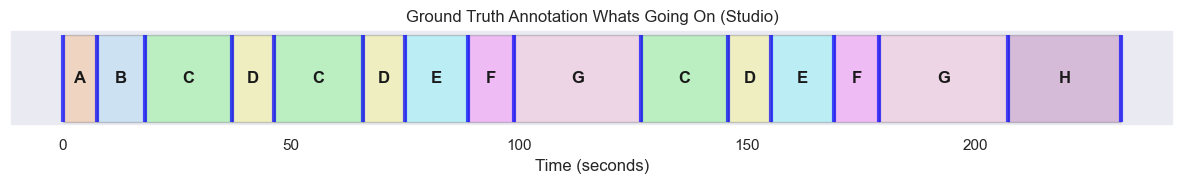

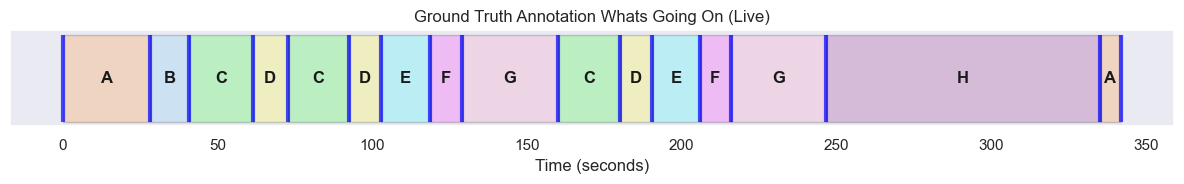

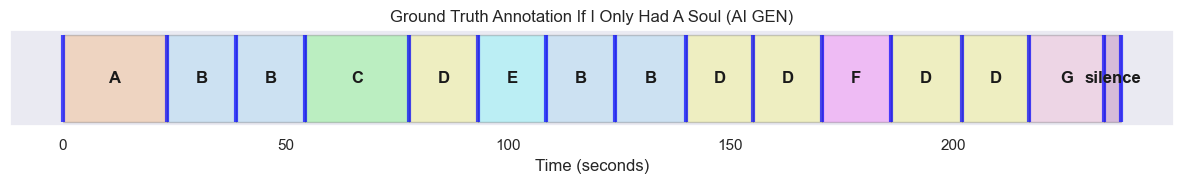

In [7]:
visualiseSegments(ori_jam, 'Whats Going On (Studio)')
visualiseSegments(liv_jam, 'Whats Going On (Live)')
visualiseSegments(gen_jam, 'If I Only Had A Soul (AI GEN)')

### **4. Initial Comparison (Original vs Live)**

Now I will use the new Ground Truth annotations to compare the original recording and the live recording or Whats Going On and calculate the...
* Precision
* Recall
* F-Measure

...of the two tracks, I will then use these results to discuss the simularities and the differences of the tracks

In [8]:
def compareJamBoundaries(ori, liv, window):
    ##  Gathers annotation details from previously defined getter (Look at 3. Visualisation)
    ori_starts, ori_ends, ori_labels = getSegmentAnnotationInfo(ori)
    liv_starts, liv_ends, liv_labels = getSegmentAnnotationInfo(liv)

    ##  Converts the data into a format readable by mir_eval
    ori_intervals = np.array(list(zip(ori_starts, ori_ends)))
    ori_labels = np.array(ori_labels)
    liv_intervals = np.array(list(zip(liv_starts, liv_ends)))
    liv_labels = np.array(liv_labels)


    ##  Original (REF) vs Live (EST)
    P1, R1, F1 = mir_eval.segment.detection(
        ori_intervals, liv_intervals, window=window
    )

    ##  Live (REF) vs Original (EST)
    P2, R2, F2 = mir_eval.segment.detection(
        liv_intervals, ori_intervals, window=window
    )

    P = (P1 + P2) / 2  ##  Calculate Overall Precision
    R = (R1 + R2) / 2  ##  Calculate Overall Recall
    F = (F1 + F2) / 2  ##  Calculate Overall F-measure

    print(f"Precision: ", P)
    print(f"Recall: ", R)
    print(f"F-measure: ", F)

    O = len(ori_starts)-1  ##  Num of internal boundaries of original recording
    L = len(liv_starts)-1  ##  Num of internal boundaries of live recording

    oTP = O * P   ##  Num of True Positives for aligning original recording boundaries
    lTP = L * P   ##  Num of True Positives for aligning original recording boundaries

    print("TP for Original: ", round(oTP))
    print("TP for Live: ", round(lTP))


In [9]:
compareJamBoundaries(ori_jam, liv_jam, 0.5) 

Precision:  0.06066176470588235
Recall:  0.06066176470588235
F-measure:  0.06060606060606061
TP for Original:  1
TP for Live:  1


#### **What do these results tell us?**

Quantitively the recordings couldn't be more different, with all the Precision, Recall and F-measure all roughly hitting the **0.06** mark. A result 0.06 for each value means that only **~6%** of the boundaries in the two annotations match within 0.5s (the suggested figure), or **~94%** of the boundaries do not align between the Original and the Live recording.

We can then use this percentage to calculate the number of boundaries that aligned for each song (or number of true positives), as you can see for both songs only 1 boundary aligned.

The reason for this huge misalignment is because both songs have slightly different tempos, with the live being at 92bpm and the original being at 102bpm, this difference leads to the original recording hitting boundaries much sooner than the live one. To account for this I will run the calculations again, this time with a 3s window instead of a 0.5s, to allow for this slight tempo difference.

In [10]:
compareJamBoundaries(ori_jam, liv_jam, 3)

Precision:  0.3033088235294118
Recall:  0.3033088235294118
F-measure:  0.30303030303030304
TP for Original:  4
TP for Live:  5


As you can see this yields much higher number of True Positives, most probably from earlier in the song before the two recordings become too misaligned for boundaries to be matched.

While quantitivly the songs are quite different, they are quite similar structure wise, both songs feature primarily the same structure, with the live version only deviating by having a longer outro (something very common in live performances) and having ambient crowd noise at the end.

However now that I have analysed the ground truth structure of the song I do forsee some issues with the segmentation process. First of all, while to the human ear these recordings both have a clear structure (clear verses, prechoruses, choruses,  etc), I fear that the musical contents consistency throughout these segments will make it difficult for any segmentation pipeline to distinguish between them.

## ***Part 2: Feature Analysis (10 Marks)***

### **1. Extraction**

In [11]:
##  Gathers the raw audio and sample rate from mp3
def loadTrack(mp3Name):
    fileName = mp3Name + ".mp3"
    x, Fs = librosa.load(fileName, sr=None)
    return x, Fs

In [12]:
##  Returns the MFSS of a recording (The texture of the recording over time)
def calculateMFCC(y, sr, coNum):
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=coNum)
    return mfccs

In [13]:
##  Returns the Chromagram of the recording (The pitch of the recording over time)
def calculateChromagram(y, sr):
    H = 1024  ##  Hop size

    chromagram = librosa.feature.chroma_cqt(
        y=y, sr=sr, tuning=0, norm=2, hop_length=H
    )

    Fs_C = sr / H  ##  Sample Rate of the chromagram

    return chromagram, Fs_C


In [14]:
##  Load Tracks
ori_y, ori_sr = loadTrack("whats_going_on")
liv_y, liv_sr = loadTrack("whats_going_on_live")
gen_y, gen_sr = loadTrack("if_i_only_had_a_soul")

##  Get Chromagrams
ori_chroma, ori_Fs = calculateChromagram(ori_y, ori_sr)
liv_chroma, liv_Fs = calculateChromagram(liv_y, liv_sr)
gen_chroma, gen_Fs = calculateChromagram(gen_y, gen_sr)

##  Get MFCCs
ori_mfcc = calculateMFCC(ori_y, ori_sr, 13)
liv_mfcc = calculateMFCC(liv_y, liv_sr, 13)
gen_mfcc = calculateMFCC(gen_y, gen_sr, 13)

c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### **2. Visualisation**


##### **Chromagram Unprocessed Results**

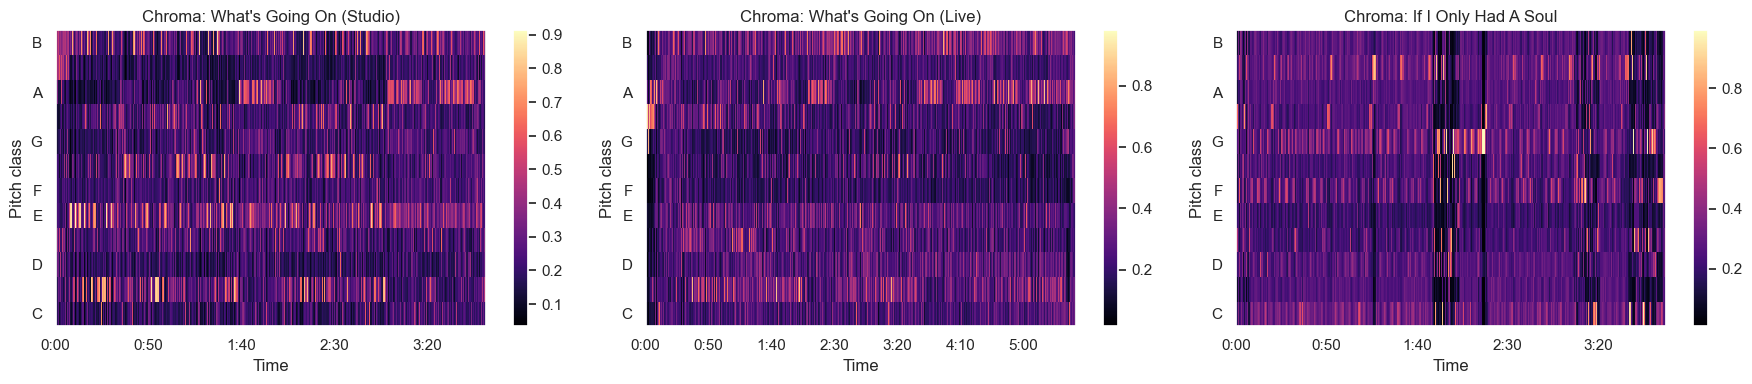

In [15]:
plt.figure(figsize=(18, 4))

##  Plot Whats Going on (Studio) chromagram
plt.subplot(1, 3, 1)
librosa.display.specshow(
    ori_chroma,
    x_axis='time',
    y_axis='chroma',
    sr=ori_Fs,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("Chroma: What's Going On (Studio)")

##  Plot Whats Going On (Live) Chromagram
plt.subplot(1, 3, 2)
librosa.display.specshow(
    liv_chroma,
    x_axis='time',
    y_axis='chroma',
    sr=liv_Fs,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("Chroma: What's Going On (Live)")

##  Plot If I Only had A Soul (AI generated) Chromagram
plt.subplot(1, 3, 3)
librosa.display.specshow(
    gen_chroma,
    x_axis='time',
    y_axis='chroma',
    sr=gen_Fs,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("Chroma: If I Only Had A Soul")

##  Displays Plot
plt.tight_layout()
plt.show()

##### **MSFF Unprocessed Results**

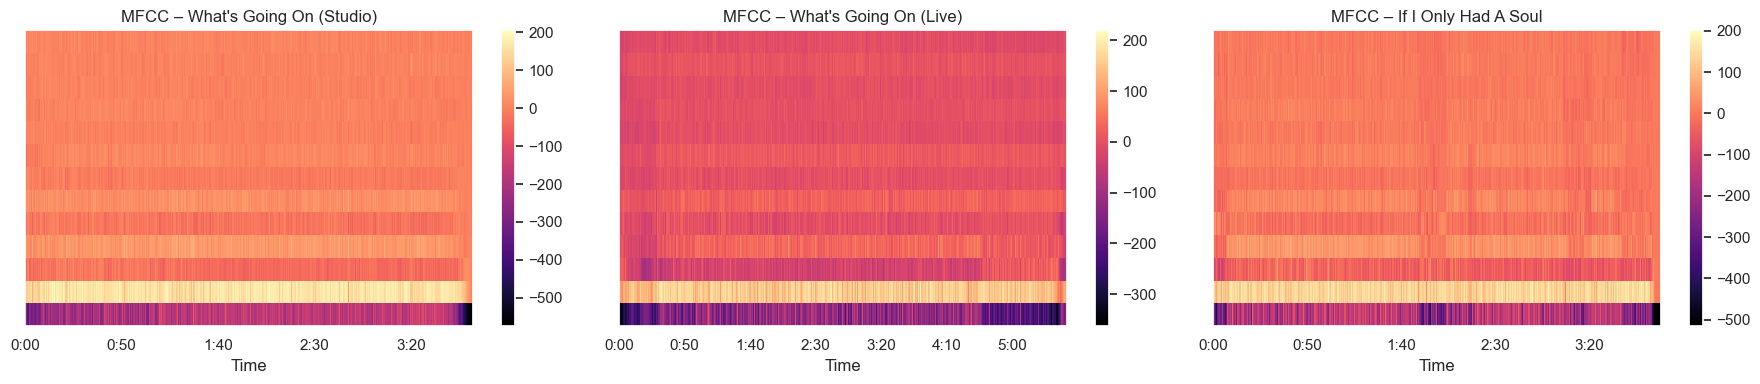

In [16]:
plt.figure(figsize=(18, 4))

##  Plots What's Going On (Studio) MFCC
plt.subplot(1, 3, 1)
librosa.display.specshow(
    ori_mfcc,
    x_axis='time',
    sr=ori_sr/512,   # MFCC feature rate
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – What's Going On (Studio)")

##  Plots What's Going On (Live) MFCC
plt.subplot(1, 3, 2)
librosa.display.specshow(
    liv_mfcc,
    x_axis='time',
    sr=liv_sr/512,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – What's Going On (Live)")

##  Plots If I Only Had A Soul (AI Generated) MFCC
plt.subplot(1, 3, 3)
librosa.display.specshow(
    gen_mfcc,
    x_axis='time',
    sr=gen_sr/512,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – If I Only Had A Soul")

##  Shows Results
plt.tight_layout()
plt.show()

### **3. Pre-Processing**

In [17]:
def calculateProcessedChromagram(y, sr, H, median_len, down_sampling):

    ##  Calculates Chroma with extra bins
    chroma = librosa.feature.chroma_cqt(
        y=y, sr=sr, tuning=0, norm=2,
        hop_length=H, bins_per_octave=36, n_chroma=12
    )
    Fs_C = sr / H

    ##  Applies Median smoothing and downsampling
    chroma, Fs_X = libfmp.c3.c3s1_post_processing.median_downsample_feature_sequence(
        chroma,
        Fs_C,
        filt_len=median_len,     
        down_sampling=down_sampling
    )

    ##  Normalises Results
    chroma = libfmp.c3.c3s1_post_processing.normalize_feature_sequence(
        chroma, norm='2', threshold=0.0001
    )

    return chroma, Fs_X



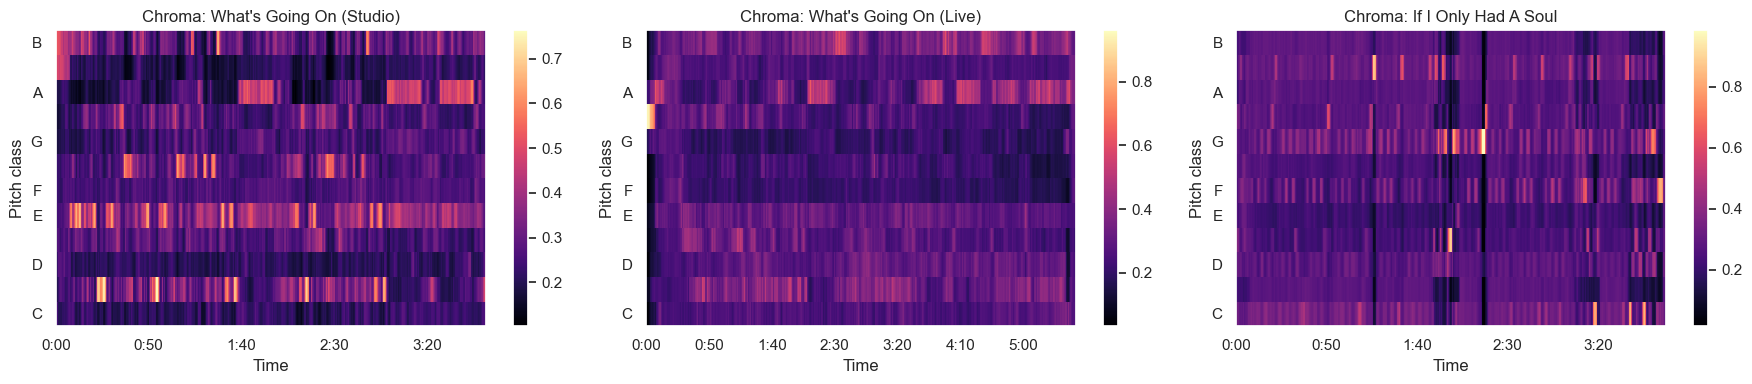

In [18]:
##  Gets Processed Chromagrams
ori_processedChroma, ori_Fs_X = calculateProcessedChromagram(ori_y, ori_sr, 2048, 51, 4)
liv_processedChroma, liv_Fs_X = calculateProcessedChromagram(liv_y, liv_sr, 2048, 71, 4)
gen_processedChroma, gen_Fs_X = calculateProcessedChromagram(gen_y, gen_sr, 2048, 51, 4)

plt.figure(figsize=(18, 4))

##  Plot What's Going On (Studio) Processed Chroma
plt.subplot(1, 3, 1)
librosa.display.specshow(
    ori_processedChroma,
    x_axis='time',
    y_axis='chroma',
    sr=ori_Fs_X,
    hop_length=1,
    cmap='magma'         
)
plt.colorbar()
plt.title("Chroma: What's Going On (Studio)")

##  Plot What's Going On (Live) Processed Chroma
plt.subplot(1, 3, 2)
librosa.display.specshow(
    liv_processedChroma,
    x_axis='time',
    y_axis='chroma',
    sr=liv_Fs_X,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("Chroma: What's Going On (Live)")

##  If I Only Had A Soul (AI Generated) Processed Chroma
plt.subplot(1, 3, 3)
librosa.display.specshow(
    gen_processedChroma,
    x_axis='time',
    y_axis='chroma',
    sr=gen_Fs_X,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("Chroma: If I Only Had A Soul")

##  Display Results
plt.tight_layout()
plt.show()

The function above creates a new chromagram, adds pre-processing, and outputs a smoothed, downsampled chromagram and the new frame rate.


The pre-processing pipeline

- Creates a chromagram, with **three bins per pitch** instead of 1, this increases the robustness of the chromagram and allows it to more easily seperate harmonically dense sections.
- **Applies a median smoothing filter** to the chromagram, Median filtering was chosen because it removes transient noise while preserving sharp structural boundaries. Unlike linear smoothing methods, it does not blur harmonic transitions, making it ideal for chromagram and novelty curve refinement in structural segmentation tasks.
- **Downsamples the chromagram**, Downsampling allows the chromagram to focus less on frame-level noise and emphasise long-term harmonic structure, which is essential when it comes to reliable structural segmentation.

The three parameters that have the most effect on the outcome of the chromagram are 
* Median Filter Length
* Hop Length
* Downsampling level

I have made these parameters adjustable as each recording will require different values, for instance the live recording has more high level noise than the original, so it needs a smaller median filter length so important segmentational features dont get smoothed out with the high level noise

As you can see from the results above, the chromagrams are now smoother and less noisy, this will make it easier to extract useful information out of them.


In [19]:
def calculateProcessedMFCC(y, sr, H, M_len, D):
    ##  Compute MFCCs
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, hop_length=H)

    Fs_MFCC = sr / H   ##  MFCC Sample Rate
    
    ##  Applies Median Smoothing Filter and Downsamples
    mfcc, fs_M = libfmp.c3.c3s1_post_processing.median_downsample_feature_sequence(
        mfcc, 
        Fs_MFCC, 
        filt_len=M_len, 
        down_sampling=D
    )
    
    ##  Normalises Results
    mfcc = libfmp.c3.normalize_feature_sequence(mfcc, norm='2')

    return mfcc, fs_M

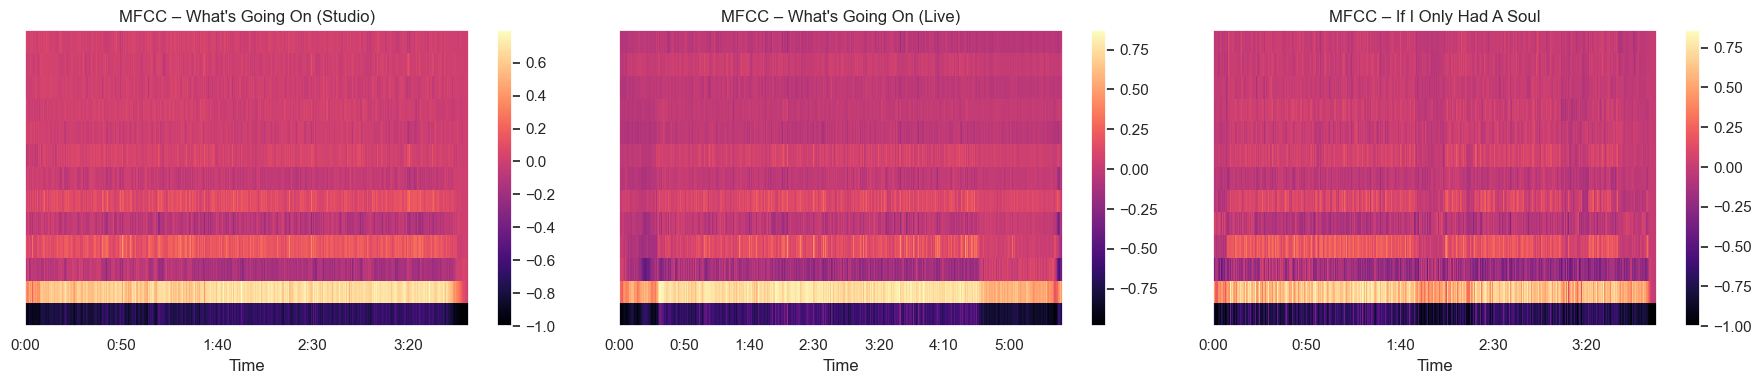

In [20]:
ori_mfcc_processed, ori_fs_M = calculateProcessedMFCC(ori_y, ori_sr, 512, 9, 4)
liv_mfcc_processed, liv_fs_M = calculateProcessedMFCC(liv_y, liv_sr, 1024, 13, 4)
gen_mfcc_processed, gen_fs_M = calculateProcessedMFCC(gen_y, gen_sr, 512, 9, 4)

plt.figure(figsize=(18, 4))

plt.subplot(1, 3, 1)
librosa.display.specshow(
    ori_mfcc_processed,
    x_axis='time',
    sr=ori_fs_M,   # MFCC feature rate
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – What's Going On (Studio)")

plt.subplot(1, 3, 2)
librosa.display.specshow(
    liv_mfcc_processed,
    x_axis='time',
    sr=liv_fs_M,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – What's Going On (Live)")

plt.subplot(1, 3, 3)
librosa.display.specshow(
    gen_mfcc_processed,
    x_axis='time',
    sr=gen_fs_M,
    hop_length=1,
    cmap='magma'
)
plt.colorbar()
plt.title("MFCC – If I Only Had A Soul")

plt.tight_layout()
plt.show()


The function above creates a new MFCC, this time adding the parameter of hop length, while MFCC automatically has a hop length ofo 512 (which is normally optimal for most recordings), I want the ability to change it depending on the track that is being analysed. For instance you can see I have applied a higher hop length for the live track as live recordings sometimes have timber spikes unrelated to the song itself (crowd noise, technical issues)

* **Hop Length Decreases** as recording timbre changes more frequently than pitch, meaning a higher hop length could remove important features 
* **Median Filter Length decreases** as too much smoothing could remove important features from the mfcc
* **Downsizing stays the same** in order to allow for sudden changes in timbre unrelated to the song structure itself to become less heavily weighted.

The MFCC Preprocessing yet again has the same three parameters which most change the output
* Median Filter Length
* Hop Length
* Downsampling level




## ***Part 3: SSM & Novelty-based Segmentation (25 Marks)***

### **1. SSM Construction**

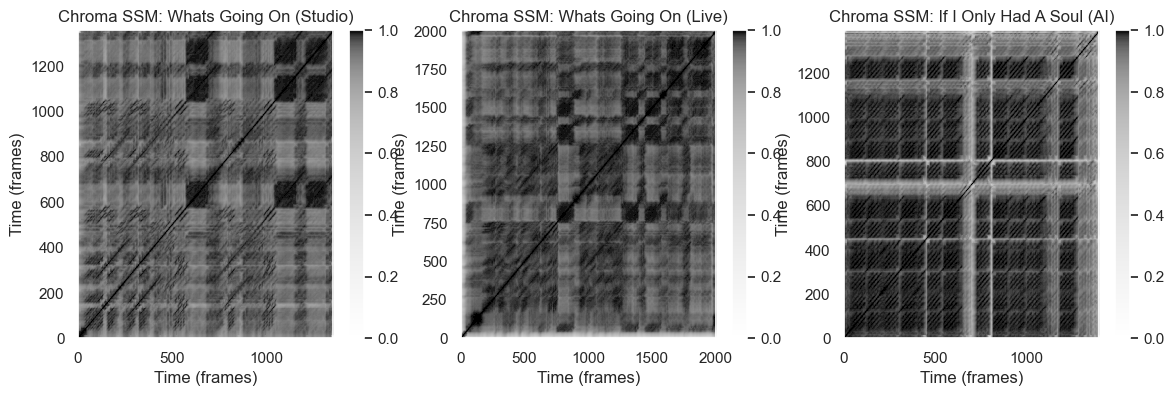

In [21]:
##  Calculates a standard SSM that is tempo invariant
def calculateSSM(X):
    tempo_rel_set=np.array([1])
    shift_set=np.array([0])

    S, _ = libfmp.c4.compute_sm_ti(X, X, L=16, tempo_rel_set=tempo_rel_set, shift_set=shift_set, direction=2)
    return S

##  Calculates the duration of the recording
def calculateDuration(y, sr):
    return (y.shape[0]) / sr

##  Calculates unprocessed SSM for chroma
ori_S = calculateSSM(ori_processedChroma)
liv_S = calculateSSM(liv_processedChroma)
gen_S = calculateSSM(gen_processedChroma)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

libfmp.c4.subplot_matrix_colorbar(ori_S, fig, ax[0], clim=[0,1], 
                                  title='Chroma SSM: Whats Going On (Studio)', xlabel='Time (frames)', ylabel='Time (frames)')

libfmp.c4.subplot_matrix_colorbar(liv_S, fig, ax[1], clim=[0,1], 
                                  title='Chroma SSM: Whats Going On (Live)', xlabel='Time (frames)', ylabel='Time (frames)')

libfmp.c4.subplot_matrix_colorbar(gen_S, fig, ax[2], clim=[0,1], 
                                  title='Chroma SSM: If I Only Had A Soul (AI)', xlabel='Time (frames)', ylabel='Time (frames)')

plt.show()

#### **Chroma SSMs Analysis**

Above I have used the processed chromagrams made in the previous section to generate Self-Simularity Matrices, hoping to extract data which could aid in segmentation.
Here are my findings for the three songs analysed.

* What's Going On: Original

        The main diagonal represents the main timeline of the song, along this diagonal you can see darker squares, these squares represent sections of the song which have a high simularity, comparing this to the ground truth analysis of the song, you can see already it is picking up on segment boundaries.

        All over the graph, you can also see black lines that run parallel to the main diagonal, these represent repeated sections. If you look on the SSM at x: 250 y: 100 you can see one of these lines, this specific line shows that the SSM is recognising the simualrity between two of the verses of the song.

* What's Going On: Live

        This SSM actually produced similar results to the Original version, looking at the two you can see one shape that both have that is almost identical along the main diagonal, however since the live version has an extended outro, they appear at different times in the recordings.

        This shape represents the Post-Chorus, in the original it plays after both choruses and repeats one time before the end of the song, however in the live version it plays 2 extra times (the extended outro) with dropped out instruments, this is why in the live SSM you can see the simularity drops for these last 2 repeats

* If I Only Had A Soul: AI Generated

        This SSM looks different from the previous two as it shows a high level of simularity across the entire song. This looks confusing until you listen to the track itself, which has very little harmonic variation, while it does have a verse, pre-chorus, chorus structure, there is little musical variation between them, with all the segments being in the same key and having the same chords, tempo and instrumentation. This will make segmentation difficult and make the SSM processing very important.


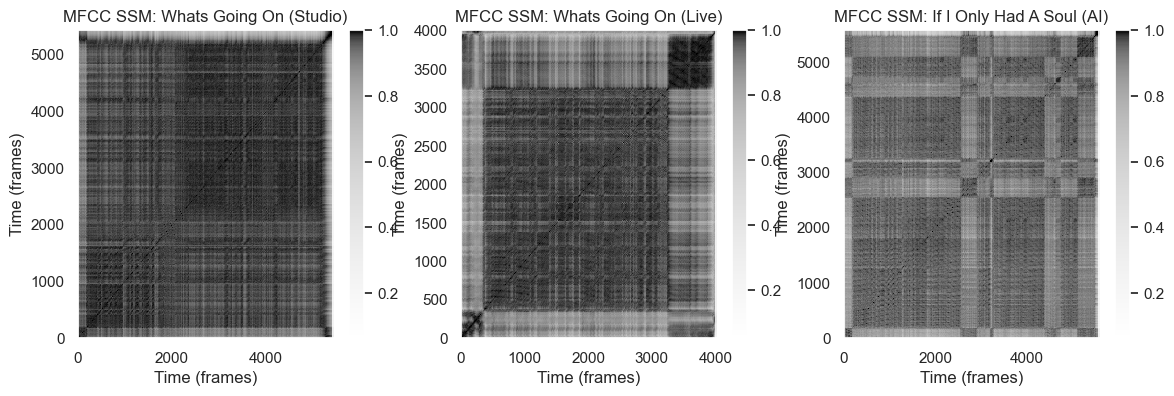

In [22]:
def calculateFMCC_SSM(X):
    tempo_rel_set=np.array([1])
    shift_set=np.array([0])

    S, _ = libfmp.c4.compute_sm_ti(X, X, L=16, tempo_rel_set=tempo_rel_set, shift_set=shift_set, direction=2)
    return S

def calculateDuration(y, sr):
    return (y.shape[0]) / sr

ori_S_FMCC = calculateFMCC_SSM(ori_mfcc_processed)
liv_S_FMCC = calculateFMCC_SSM(liv_mfcc_processed)
gen_S_FMCC = calculateFMCC_SSM(gen_mfcc_processed)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

libfmp.c4.subplot_matrix_colorbar(ori_S_FMCC, fig, ax[0], 
                                  title='MFCC SSM: Whats Going On (Studio)', xlabel='Time (frames)', ylabel='Time (frames)')


libfmp.c4.subplot_matrix_colorbar(liv_S_FMCC, fig, ax[1],
                                  title='MFCC SSM: Whats Going On (Live)', xlabel='Time (frames)', ylabel='Time (frames)')

libfmp.c4.subplot_matrix_colorbar(gen_S_FMCC, fig, ax[2],
                                  title='MFCC SSM: If I Only Had A Soul (AI)', xlabel='Time (frames)', ylabel='Time (frames)')

plt.show()

#### **MFCC SSMs Analysis**

The above graphs show the results of creating SSMs from each of the 3 songs using MFCC features. MFCCs capture timbre rather than harmony, so their SSMs naturally look different from the chroma‑based ones. Here are some observations from these graphs:
For All Three Recordings
- The main diagonal is present, confirming that the SSM has been computed correctly from the MFCC feature sequences.
- Repeated regions can still be seen, but they appear less sharp and less rectangular than in the chroma SSMs. This reflects the fact that timbre varies more within repeated sections than harmony does.
- Boundaries between sections are visible but softer, showing that timbral changes do not always align perfectly with structural boundaries in the music.
- There is noticeably more local variation (“texture”) across the matrices. This is expected because MFCCs respond strongly to small changes in vocal tone, articulation, instrumentation, and expressive performance.
- Side diagonals are weaker and more fragmented, indicating that timbral similarity across repeated sections is less consistent than harmonic similarity.

These features show that the MFCC preprocessing has 
produced meaningful SSMs that capture broad structural repetition, but with greater internal variability due to the fast‑changing nature of timbre. This contrasts with the chroma SSMs, which appear cleaner and more block‑like because harmony changes more slowly and is more stable across performances.

After analysing both Chroma and MFCC Self-Similarity Matrices, I have decided to move forward with chroma, as I feel it will be more useful when it comes to segmentation.

### **2. Novelty Based Segmentation**


For the Novelty Based Segmentation approach, instead of using 1 kernal, I have implemented a multi-scale kernal algorithm that computes the novelty curve for a smaller kernal (for detecting fast changes) and a larger kernal (for detecting slower changes) and averaged the two. this way the pipeline will be more robust to tone changes.

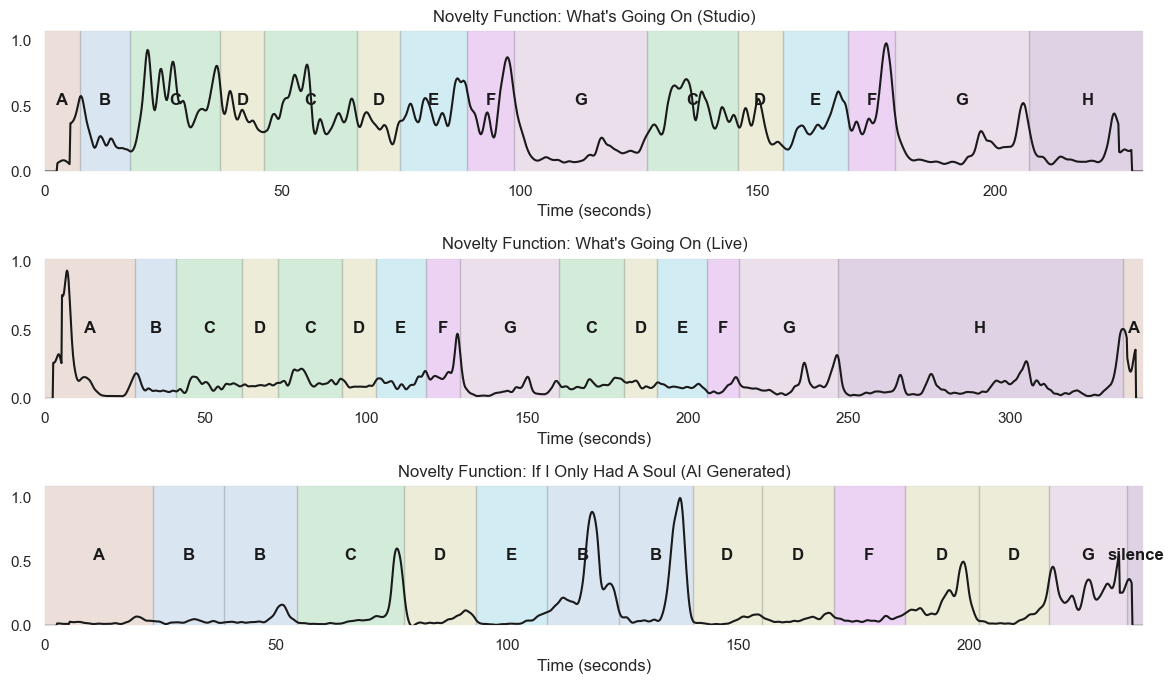

In [23]:
def calculateNoveltyCurve(S, L_list=[16, 32], var=0.5):
    novs = []
    for L in L_list:
        kernel = libfmp.c4.compute_kernel_checkerboard_gaussian(L=L, var=var)
        nov = libfmp.c4.compute_novelty_ssm(S, kernel=kernel, L=L, exclude=True)
        novs.append(nov / (nov.max() + 1e-10))
    nov = sum(novs) / len(novs)
    return nov

# Compute novelty curves + peaks
ori_nov = calculateNoveltyCurve(ori_S)
liv_nov = calculateNoveltyCurve(liv_S)
gen_nov = calculateNoveltyCurve(gen_S)

# Segment annotations
ori_segments = list(zip(*getSegmentAnnotationInfo(ori_jam)))
liv_segments = list(zip(*getSegmentAnnotationInfo(liv_jam)))
gen_segments = list(zip(*getSegmentAnnotationInfo(gen_jam)))

# Plot
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=False)

# --- ORI ---
libfmp.b.plot_signal(ori_nov, Fs=ori_Fs_X, ax=ax[0], color='k')
libfmp.b.plot_segments_overlay(ori_segments, ax=ax[0], alpha=0.1, edgecolor='k')
ax[0].set_title("Novelty Function: What's Going On (Studio)")

# --- LIV ---
libfmp.b.plot_signal(liv_nov, Fs=liv_Fs_X, ax=ax[1], color='k')
libfmp.b.plot_segments_overlay(liv_segments, ax=ax[1], alpha=0.1, edgecolor='k')
ax[1].set_title("Novelty Function: What's Going On (Live)")

# --- GEN ---
libfmp.b.plot_signal(gen_nov, Fs=gen_Fs_X, ax=ax[2], color='k')
libfmp.b.plot_segments_overlay(gen_segments, ax=ax[2], alpha=0.1, edgecolor='k')
ax[2].set_title("Novelty Function: If I Only Had A Soul (AI Generated)")

plt.tight_layout()
plt.show()

I have decided to use adaptive peak picking on the computed novelty curve as it automatically adjusts to local dynamics, meaning it is robust to volume changes throughout the recording.

I also enhance the contrast by subtracting the local average from the novelty curve, this stops any peak bias towards louder areas and helps identify important features more effectivly

Finally I added parameters which define
- Minimum Peak Prominence
- Minimum Peak Distance
In an attempt to improve over-segmentation

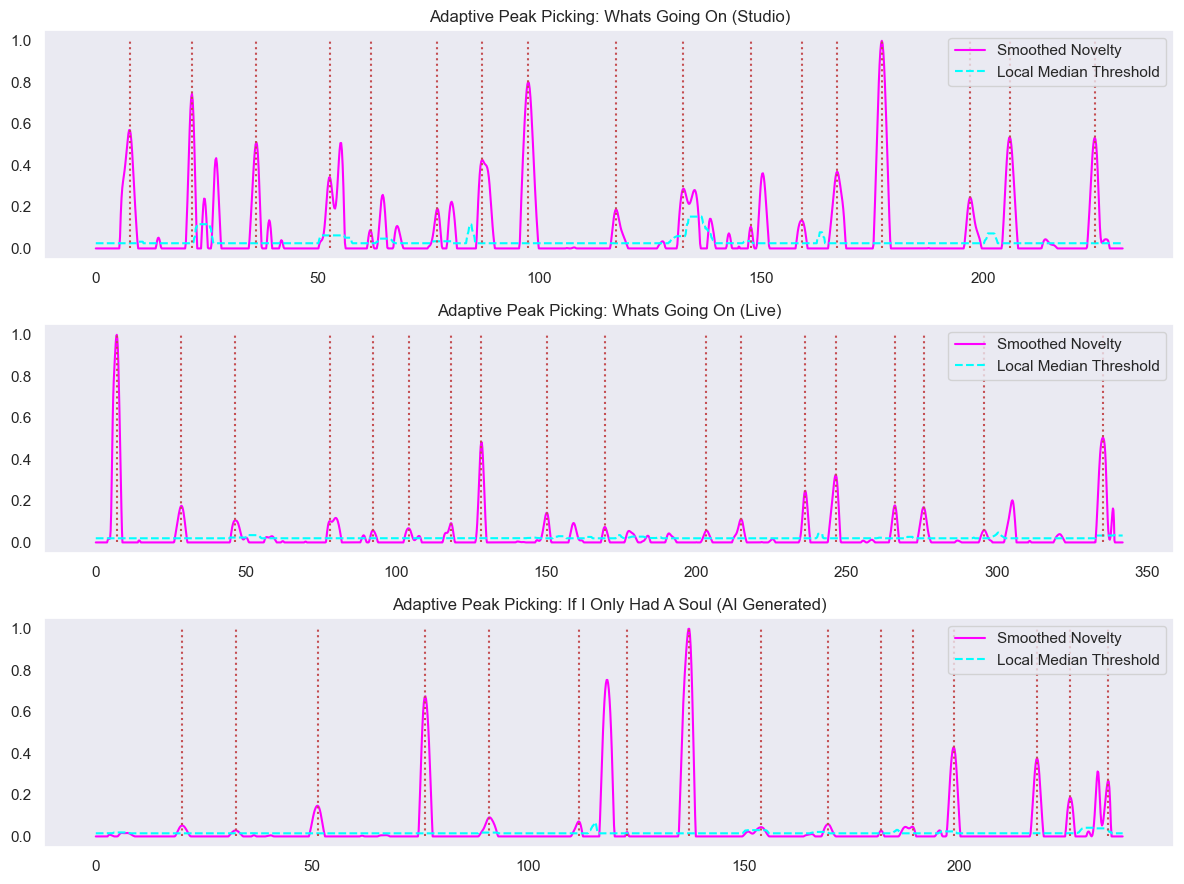

In [24]:
def calculateNoveltyPeaks(nov, median_len=51, offset_factor=0.03, min_prom=0.05, min_dist=20):

    ##  Smooths the novelty curve
    nov_smooth = scipy.ndimage.gaussian_filter1d(nov, sigma=2)

    ##  Enhances the contrast of the novelty curve in order to improve segmentation
    ma = scipy.ndimage.uniform_filter1d(nov_smooth, size=median_len)
    nov_contrast = np.maximum(0, nov_smooth - ma)

    ##  Normalise output
    nov_norm = nov_contrast / (np.max(nov_contrast) + 1e-10)

    ##  Applies adaptive peak detection
    offset = offset_factor * np.max(nov_norm)
    threshold_local = scipy.ndimage.median_filter(nov_norm, size=median_len) + offset

    peaks = []
    for i in range(1, len(nov_norm) - 1):
        if nov_norm[i-1] < nov_norm[i] and nov_norm[i] > nov_norm[i+1]:
            if nov_norm[i] > threshold_local[i]:
                if nov_norm[i] - threshold_local[i] > min_prom:
                    if not peaks or (i - peaks[-1]) > min_dist:
                        peaks.append(i)

    return nov_norm, threshold_local, np.array(peaks)


##  Calculates Novelty Curves and Peaks for the original recording
ori_time_axis = np.arange(len(ori_nov)) / ori_Fs_X
ori_nov_smooth, ori_threshold_local, ori_peaks = calculateNoveltyPeaks(ori_nov, median_len=61, offset_factor=0.025,min_prom=0.06,min_dist=45)

##  Calculates Novelty Curves and Peaks for the live recording
liv_time_axis = np.arange(len(liv_nov)) / liv_Fs_X
liv_nov_smooth, liv_threshold_local, liv_peaks = calculateNoveltyPeaks(liv_nov, median_len=71, offset_factor=0.02,min_prom=0.035,min_dist=55)

##  Calculates Novelty Curves and Peaks for the AI Generated recording
gen_time_axis = np.arange(len(gen_nov)) / gen_Fs_X
gen_nov_smooth, gen_threshold_local, gen_peaks = calculateNoveltyPeaks(gen_nov, median_len=51, offset_factor=0.015,min_prom=0.004,min_dist=40)


##  Visualises Result
fig, ax = plt.subplots(3, 1, figsize=(12, 9))

##  Plots Original novelty curve and detected peaks
ax[0].plot(ori_time_axis, ori_nov_smooth, color='magenta', label='Smoothed Novelty')
ax[0].plot(ori_time_axis, ori_threshold_local, color='cyan', linestyle='--', label='Local Median Threshold')
ax[0].vlines(ori_peaks / ori_Fs_X, ymin=0, ymax=max(ori_nov_smooth), color='r', linestyle=':')
ax[0].set_title('Adaptive Peak Picking: Whats Going On (Studio)')
ax[0].legend(loc='upper right')

##  Plots Live novelty curve and detected peaks
ax[1].plot(liv_time_axis, liv_nov_smooth, color='magenta', label='Smoothed Novelty')
ax[1].plot(liv_time_axis, liv_threshold_local, color='cyan', linestyle='--', label='Local Median Threshold')
ax[1].vlines(liv_peaks / liv_Fs_X, ymin=0, ymax=max(liv_nov_smooth), color='r', linestyle=':')
ax[1].set_title('Adaptive Peak Picking: Whats Going On (Live)')
ax[1].legend(loc='upper right')

##  Plots AI Generated novelty curve and detected peaks
ax[2].plot(gen_time_axis, gen_nov_smooth, color='magenta', label='Smoothed Novelty')
ax[2].plot(gen_time_axis, gen_threshold_local, color='cyan', linestyle='--', label='Local Median Threshold')
ax[2].vlines(gen_peaks / gen_Fs_X, ymin=0, ymax=max(gen_nov_smooth), color='r', linestyle=':')
ax[2].set_title('Adaptive Peak Picking: If I Only Had A Soul (AI Generated)')
ax[2].legend(loc='upper right')

##  Displays results
plt.tight_layout()
plt.show()



### **3. Evaluation**

In [25]:
def evaluateBoundaries(jam, peaks, Fs_X):

    ## Calculate ground truth boundaries
    starts, _, _ = getSegmentAnnotationInfo(jam)
    gt_boundaries = np.array(starts[1:])
    gt_boundaries = np.unique(gt_boundaries)

    ## Calculate peak detected boundaries
    est_boundaries = np.array(peaks) / Fs_X

    TOLERANCE_WINDOW = 3


    ##  Calculate precision, f-measure and recall between the two
    F, P, R = mir_eval.onset.f_measure(gt_boundaries, est_boundaries, window=TOLERANCE_WINDOW)

    return (P, R, F)

ori_evaluation = evaluateBoundaries(ori_jam, ori_peaks, ori_Fs_X)
liv_evaluation = evaluateBoundaries(liv_jam, liv_peaks, liv_Fs_X)
gen_evaluation = evaluateBoundaries(gen_jam, gen_peaks, gen_Fs_X)

print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_evaluation[0]:.3f}")
print(f"Recall (R):    {ori_evaluation[1]:.3f}")
print(f"F-measure (F): {ori_evaluation[2]:.3f}")
print("\n")
print(f"--- Evaluation Results: Whats Going On (Live)")
print(f"Precision (P): {liv_evaluation[0]:.3f}")
print(f"Recall (R):    {liv_evaluation[1]:.3f}")
print(f"F-measure (F): {liv_evaluation[2]:.3f}")
print("\n")
print(f"--- Evaluation Results: If I Only Had A Soul (AI Gen)")
print(f"Precision (P): {gen_evaluation[0]:.3f}")
print(f"Recall (R):    {gen_evaluation[1]:.3f}")
print(f"F-measure (F): {gen_evaluation[2]:.3f}")



--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.529
Recall (R):    0.643
F-measure (F): 0.581


--- Evaluation Results: Whats Going On (Live)
Precision (P): 0.500
Recall (R):    0.600
F-measure (F): 0.545


--- Evaluation Results: If I Only Had A Soul (AI Gen)
Precision (P): 0.500
Recall (R):    0.571
F-measure (F): 0.533


#### **Under-Segmentation vs Over-Segmentation**

When fine tuning the parameters for the pipeline, my aim was to achieve a balanced Precision and Recall value for each of the songs, as this would achieve an output which was neither under-segmented nor over-segmented. However, as I progressed with the systematic parameter search, it became clear that a perfect balance was not only difficult to achieve, but also not necessarily desirable. The goal of the pipeline is to segment the recording into distinct, repeating sections, and aiming for a perfectly balanced segmentation forces the system to ignore smaller harmonic or timbral changes that may still be musically meaningful.

In practice, I realised that it is often better for the pipeline to slightly over-segment rather than under-segment. Over-segmentation ensures that the major structural boundaries are almost always detected, even if a few extra boundaries are introduced. These additional boundaries can be filtered or merged later, whereas missed boundaries (under-segmentation) cannot be recovered once lost. 

This idea changed the way I viewed the results and fine-tuned the pipeline, and as you can see, my results above are all slightly over segmented as a result.

---

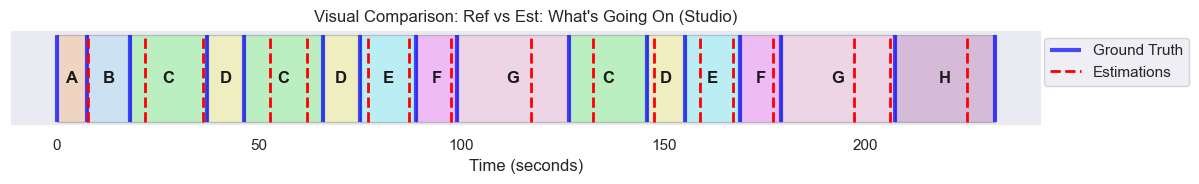

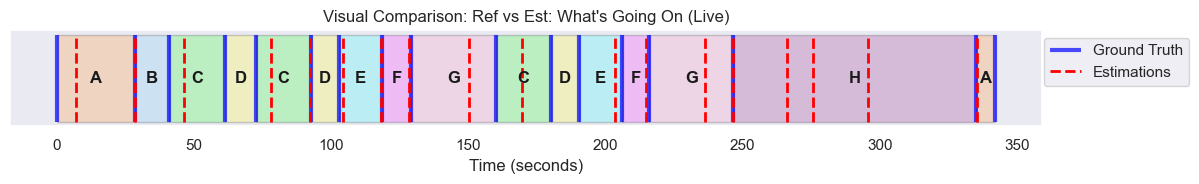

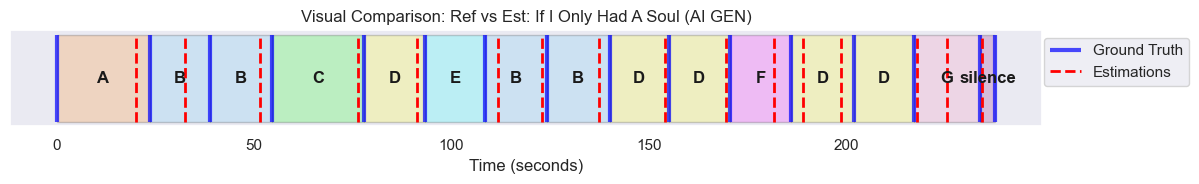

In [26]:

def compareBoundariesWithGT(segments, boundaries, Fs_X, title):
     gt_boundaries = np.array([segment[0] for segment in segments] + [segments[-1][1]])
     gt_boundaries = np.unique(gt_boundaries)

     ## Calculate peak detected boundaries
     est_boundaries = np.array(boundaries) / Fs_X

     fig, ax = plt.subplots(figsize=(12, 2))
     libfmp.b.plot_segments_overlay(segments, ax=ax, alpha=0.2, edgecolor='k')

     # Plot Ground Truth boundaries (Blue)
     ax.vlines(gt_boundaries, 0, 1, color='blue', linewidth=3, label='Ground Truth', alpha=0.7)

     # Plot Estimated boundaries (Red dashed)
     ax.vlines(est_boundaries, 0, 1, color='red', linestyle='--', linewidth=2, label='Estimations')

     pltTitle = "Visual Comparison: Ref vs Est: " + title
     ax.set_title(pltTitle)
     ax.set_xlabel('Time (seconds)')
     ax.set_yticks([])
     # Place legend outside the plot
     ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1))

     plt.tight_layout()
     plt.show()

compareBoundariesWithGT(ori_segments, ori_peaks, ori_Fs_X, "What's Going On (Studio)")
compareBoundariesWithGT(liv_segments, liv_peaks, liv_Fs_X, "What's Going On (Live)")
compareBoundariesWithGT(gen_segments, gen_peaks, gen_Fs_X, "If I Only Had A Soul (AI GEN)")

### **4. Optimisation**

#### **SSM Optimisation Pipeline**

1. Creates an SSM from the processed Chromagram that is tempo invariant
2. Normalises this SSM
3. Applies path enhancement in the form of diagonal smoothing to enhance areas of harmonic and structural simularity
4. Normalise the result of this
5. Apply a threshold to extract only relevant features and help filter out unnecassary noise

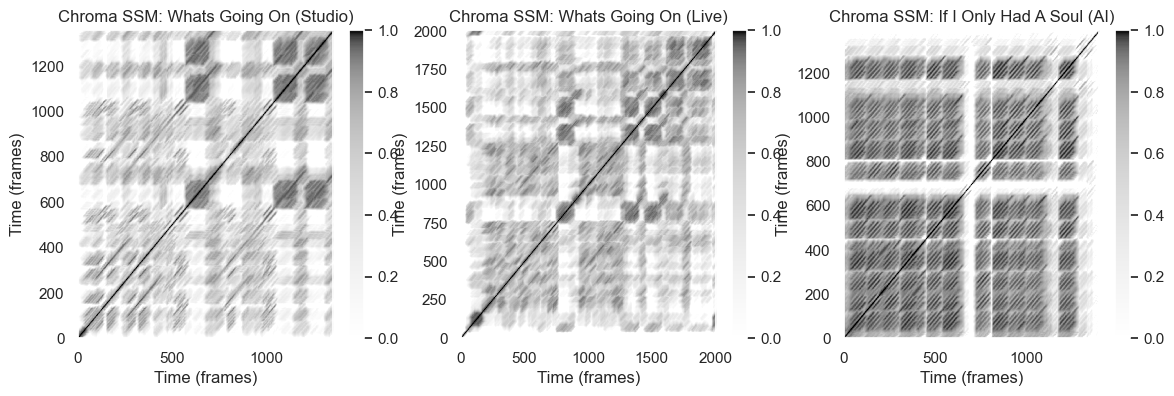

In [27]:
def calculateOptimisedSSM(X, L_path=10, threshold=0.9, penalty=-1.0):
    ##  Calculates base SSM
    S = calculateSSM(X)

    ##  Normalises the SSM
    S = S - S.min()
    S = S / (S.max() + 1e-10)

    ##  Applies diagonal smoothing in multiple directions to enhance areas of harmonic similarity
    tempo_rel_set = libfmp.c4.compute_tempo_rel_set(0.66, 1.5, 5)
    S_forward = libfmp.c4.filter_diag_mult_sm(S, L_path, tempo_rel_set=tempo_rel_set, direction=0)
    S_backward = libfmp.c4.filter_diag_mult_sm(S, L_path, tempo_rel_set=tempo_rel_set, direction=1)
    S_enhanced = np.maximum(S_forward, S_backward)

    ##  Normalises the result
    S_enhanced = S_enhanced - S_enhanced.min()
    S_enhanced = S_enhanced / (S_enhanced.max() + 1e-10)

    ##  Applies a threshold to the SSM 
    S_thresh = libfmp.c4.threshold_matrix(
        S_enhanced,
        thresh=threshold,
        strategy='relative',
        scale=True,
        penalty=penalty,
        binarize=False
    )

    return S_thresh

##  Calculate Optimised SSMs
ori_opt_S = calculateOptimisedSSM(ori_processedChroma)
liv_opt_S = calculateOptimisedSSM(liv_processedChroma)
gen_opt_S = calculateOptimisedSSM(gen_processedChroma)

##  Visualises Results
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
libfmp.c4.subplot_matrix_colorbar(ori_opt_S, fig, ax[0], clim=[0,1], 
                                  title='Chroma SSM: Whats Going On (Studio)', xlabel='Time (frames)', ylabel='Time (frames)')

libfmp.c4.subplot_matrix_colorbar(liv_opt_S, fig, ax[1], clim=[0,1], 
                                  title='Chroma SSM: Whats Going On (Live)', xlabel='Time (frames)', ylabel='Time (frames)')

libfmp.c4.subplot_matrix_colorbar(gen_opt_S, fig, ax[2], clim=[0,1], 
                                  title='Chroma SSM: If I Only Had A Soul (AI)', xlabel='Time (frames)', ylabel='Time (frames)')

plt.show()





In [28]:
##  Super paramatised function which contains the entire pipeline so far
def performBoundaryDetection(jam, y, sr, title="",
                             H=2048, chroma_median_len=41, chroma_downsample=4, 
                             SSM_L_path=20, SSM_threshold=0.9, SSM_penalty=-1, 
                             nov_L_kernal=20,
                             peak_median_len=51, peak_offset=0.03, peak_min_prom=0.5,peak_min_dist=20):
    ##  Generate Chromagram
    X, Fs_X = calculateProcessedChromagram(y, sr, H, chroma_median_len, chroma_downsample)

    ##  Generate SSM
    S = calculateOptimisedSSM(X, SSM_L_path, SSM_threshold, SSM_penalty)

    ##  Calculate Novelty Curve
    nov = calculateNoveltyCurve(S, nov_L_kernal)

    ##  Pick Peaks
    _, _, peaks = calculateNoveltyPeaks(nov, median_len=peak_median_len, offset_factor=peak_offset, min_prom=peak_min_prom,min_dist=peak_min_dist)
    
    ##  Evaluate Results
    eval = evaluateBoundaries(jam, peaks, Fs_X)

    ##  Return Results
    print(f"Precision (P): {eval[0]:.3f}")
    print(f"Recall (R):    {eval[1]:.3f}")
    print(f"F-measure (F): {eval[2]:.3f}")

    ##  Display results as a plot
    segments = list(zip(*getSegmentAnnotationInfo(jam)))
    compareBoundariesWithGT(segments,peaks, Fs_X, title)


#### **Pipeline Optimisation**

Below is the result of grid search of parameters in order to find the most optimal pipeline parameters for each of the recordings.

### **Whats Going On (Studio)** — Parameter Rationale

- **H = 2048** — balances time resolution and harmonic stability  
- **chroma_median_len = 51** — smooths chroma while preserving studio detail  
- **chroma_downsample = 4** — reduces noise, keeps harmonic structure intact  
- **SSM_L_path = 20** — captures short, clean diagonal repetitions  
- **SSM_threshold = 0.9** — keeps only strongest studio similarities  
- **SSM_penalty = -1** — sharpens contrast between matching sections  
- **nov_L_kernal = [16, 32]** — enhances boundaries at multiple time scales  
- **peak_median_len = 61** — stabilises threshold without oversmoothing  
- **peak_offset = 0.025** — slightly lowers threshold for mild over‑segmentation  
- **peak_min_prom = 0.006** — keeps subtle but meaningful studio peaks  
- **peak_min_dist = 45** — prevents duplicate peaks around same boundary  

### **Whats Going On (Live)** — Parameter Rationale

- **H = 2048** — maintains robustness against live noise  
- **chroma_median_len = 71** — heavy smoothing to suppress crowd interference  
- **chroma_downsample = 4** — reduces instability in noisy chroma  
- **SSM_L_path = 25** — longer paths help overcome noisy diagonals  
- **SSM_threshold = 0.75** — lower threshold to recover weak similarities  
- **SSM_penalty = -0.5** — softer penalty for noisy mismatches  
- **nov_L_kernal = [16, 32]** — multi‑scale novelty helps weak boundaries  
- **peak_median_len = 71** — strong smoothing stabilises noisy novelty curve  
- **peak_offset = 0.02** — low threshold boosts recall in weak peaks  
- **peak_min_prom = 0.035** — filters out noise‑driven false positives  
- **peak_min_dist = 55** — avoids clusters of noise‑induced peaks  


Precision (P): 0.500
Recall (R):    0.571
F-measure (F): 0.533


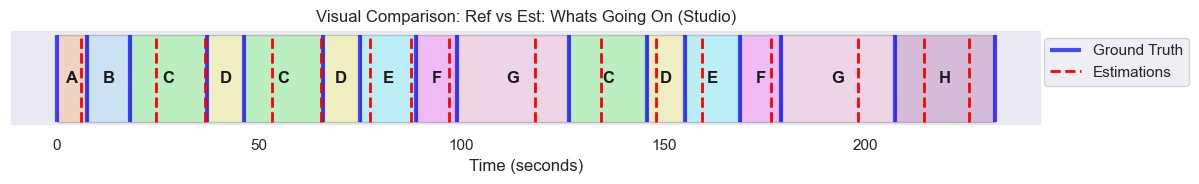

Precision (P): 0.500
Recall (R):    0.533
F-measure (F): 0.516


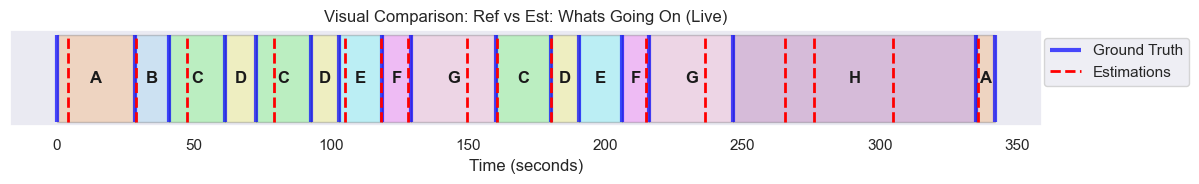

In [29]:
performBoundaryDetection(ori_jam, 
                         ori_y, 
                         ori_sr, 
                         title="Whats Going On (Studio)",
                         H=2048, 
                         chroma_median_len=51, 
                         chroma_downsample=4, 
                         SSM_L_path=20, 
                         SSM_threshold=0.9, 
                         SSM_penalty=-1, 
                         nov_L_kernal=[16, 32],
                         peak_median_len=61, 
                         peak_offset=0.025,
                         peak_min_prom=0.006,
                         peak_min_dist=45,
                        )
performBoundaryDetection(
                        liv_jam,
                        liv_y,
                        liv_sr,
                        title="Whats Going On (Live)",
                        H=2048,
                        chroma_median_len=71,
                        chroma_downsample=4,
                        SSM_L_path=25,
                        SSM_threshold=0.75,
                        SSM_penalty=-0.5,
                        nov_L_kernal=[16, 32],
                        peak_median_len=71,
                        peak_offset=0.02,
                        peak_min_prom=0.035,
                        peak_min_dist=55,
        
                    )




Overall I was able to get more consistent results for the original than the live, the reason for this being the original was recorded in a controlled setting, so all features were somewhat meaningful, whereas the live version had to account for crowd noise, microphone feedback, inconsisten timbre, all of which created false features that the pipeline struggled to differentiate from useful ones

## ***Part 4: Comparative Analysis via MSAF (30 Marks)***


### **Boundary Algorithm: Structural Features**

Structural Features is a boundary-detection algorithm that uses self-similarity patterns to extract structural cues such as repetition, section similarity and block patterns. It tends to be more robust than novelty-based methods for clear repeating sections.

I chose it as it tends to be better at analysing music with a strong form, such as soul

**Original Feature Choice**: I chose PCP as the feature for the original track as it is better at capturing the clean harmonic structure in studio mixes

**Live Feature Choice**: I chose CQT as the feature for the live track as live recordings tend to have tuning drift, which cqt handles better than other features

#### **Results**

**Original Track**: An f-measure of 0.33 indicates a weak segmentation performance. However if you look at the segment boundaries that were identified, the majority of them are exactly on the mark. The problem the algorithm ran into was under-segmentation. 

**Live Track**: An f-measure of 0.34 indicates again a weak segmentation performance. Again the boundaries it did correctly identify were accurate, but under-segmentation led to a poor performance

#### **Analysis**
There are a few reasons why this algorithm had a weak performance on both the live and original recordings failed:
* Both recordings have heavy harmonic layering, featuring harmonies, multiple instruments and changing drum beat, these things could make it hard for the algorithm to detect any substantial changes
* SF struggles with subtle segment changes, and the song features changes (predominantly in the verses and prechoruses) where the harmonality remains consistent, this could account for the under segmentation
* Specifically for the live version, SF needs a somewhat clean SSM to read from, features on the live recording such as acoustics, crowd noise or inconsistent audio levels could mess with the results





c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


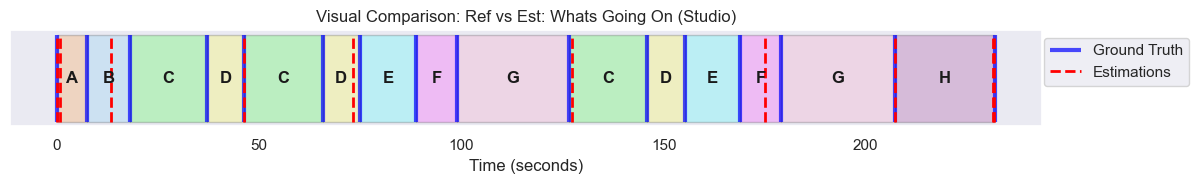

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.400
Recall (R):    0.286
F-measure (F): 0.333


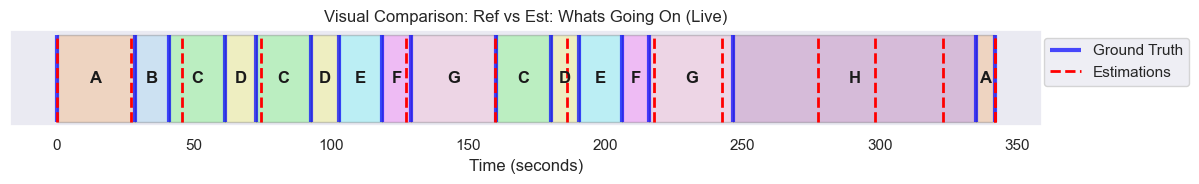

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.357
Recall (R):    0.333
F-measure (F): 0.345


In [30]:
##  Apply Structural Features Boundary-Detection to Original Track
boundaries, labels = msaf.process("whats_going_on.mp3", feature="pcp",boundaries_id="sf")
compareBoundariesWithGT(ori_segments, boundaries, 1, "Whats Going On (Studio)")
ori_sf_results = evaluateBoundaries(ori_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")

##  Apply Structural Features Boundary-Detection to Live Track
boundaries, labels = msaf.process("whats_going_on_live.mp3", feature="cqt",boundaries_id="sf")
compareBoundariesWithGT(liv_segments, boundaries, 1, "Whats Going On (Live)")
liv_sf_results = evaluateBoundaries(liv_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {liv_sf_results[0]:.3f}")
print(f"Recall (R):    {liv_sf_results[1]:.3f}")
print(f"F-measure (F): {liv_sf_results[2]:.3f}")


### **Boundary Algorithm: Spectral Clustering**

Spectral Clustering is another boundary-detection algorithm, however unlike the SF algorithm, SCluster uses graph clustering to find structural boundaries.

It treats the SSM as a graph, where the frames are the nodes, and the similarity is edge weights. It then places boundaries where the cluster arraingement changes.

This method is very effecting for music with clear repeating sections and is robust than SF when it comes to complex structure.

I have yet again used PCP feature with the original track and CQT with the live.

#### **Results**

**Original Track**: A precision, recall and f-measure of 0.5 indicates that the segmentation is balanced but only moderatally accurate, as it only found half of the true boundaries and only half of its predictions were correct. 


**Live Track**: An f-measure of 0.29 indicates a weak segmentation performance on the live track, with the precision and recall values pointing to the algorithm under-segmenting. Scluster requires the presence clear block patterns, so a result this low for a live track makes sense as reverb, crowd noise and inconstistent recording volume all lead to noisier patterns and lower similarity

#### **Analysis**
The Spectral clustering performed much better on the original than the live, there are a few reasons for this.
* Scluster performs best when ran on clean, high contrast SSMs, the original can produce this as it was expertly produced, whereas the live version has features such as reverb which produce messier SSMs
* The live variations has a slight tempo drift and inconsistent segment length, Scluster struggles with both of these and causes false boundaries, looking at the results for the live below, you can see in both F Segments, it detects a false boundary at the same point, if you listen to the recording you can hear a drum rhythm shift happens at both of these points that is not present in the original.


c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


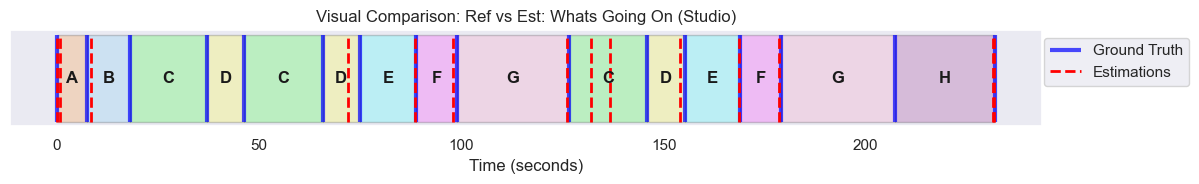

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.500
Recall (R):    0.500
F-measure (F): 0.500


c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


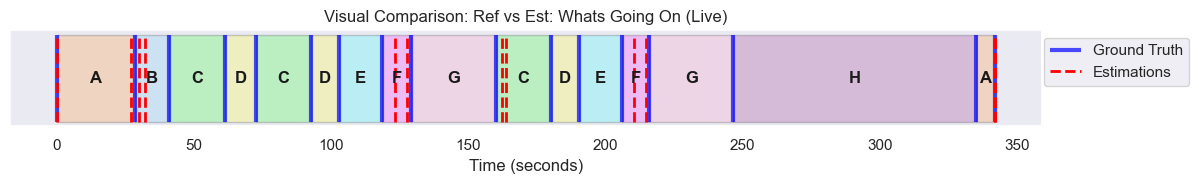

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.333
Recall (R):    0.267
F-measure (F): 0.296


In [31]:
##  Applies Spectral Clustering to the Original Track
boundaries, labels = msaf.process("whats_going_on.mp3", feature="pcp",boundaries_id="scluster")
compareBoundariesWithGT(ori_segments, boundaries, 1, "Whats Going On (Studio)")
ori_sf_results = evaluateBoundaries(ori_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")

##  Applies Spectral Clustering to the Live Track
boundaries, labels = msaf.process("whats_going_on_live.mp3", feature="cqt",boundaries_id="scluster")
compareBoundariesWithGT(liv_segments, boundaries, 1, "Whats Going On (Live)")
liv_sf_results = evaluateBoundaries(liv_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {liv_sf_results[0]:.3f}")
print(f"Recall (R):    {liv_sf_results[1]:.3f}")
print(f"F-measure (F): {liv_sf_results[2]:.3f}")


### **Structural Grouping: Spectral Clustering**

In [32]:
def visualiseMSAFGroupingResults(est_boundaries, est_labels, segments, title):
    ##  Get Ground Truth Boundaries
    gt_boundaries = np.array([seg[0] for seg in segments] + [segments[-1][1]])
    gt_boundaries = np.unique(gt_boundaries)

    ##  get Estimated Boundaries
    est_boundaries = np.array(est_boundaries, dtype=float)
    est_labels = np.array(est_labels)

    ##  Creates the colour map
    unique_labels = np.unique(est_labels)
    label_to_int = {lab: i for i, lab in enumerate(unique_labels)}
    label_ints = np.array([label_to_int[l] for l in est_labels])

    cmap = plt.get_cmap("tab20")

    ##  Creates two parallel plots
    fig, ax = plt.subplots(
        2, 1, figsize=(14, 4),
        gridspec_kw={'height_ratios': [4, 0.5], 'hspace': 0.05}
    )

    ##  Ground Truth vs Estimation Plot

    libfmp.b.plot_segments_overlay(segments, ax=ax[0], alpha=0.2, edgecolor='k')

    ##  Ground truth boundaries (blue)
    ax[0].vlines(gt_boundaries, 0, 1, color='blue', linewidth=3,
                 label='Ground Truth', alpha=0.7)

    ##  Estimated boundaries (red dashed)
    ax[0].vlines(est_boundaries, 0, 1, color='red', linestyle='--',
                 linewidth=2, label='Estimated')

    ax[0].set_title("Visual Comparison: Ref vs Est – " + title)
    ax[0].set_yticks([])
    ax[0].legend(loc='upper right')
    ax[0].set_xticks([])
    ax[0].set_xlabel("")

    ##  Structural grouping results

    for i in range(len(est_labels)):
        start = est_boundaries[i]
        end = est_boundaries[i+1]
        ax[1].axvspan(start, end, color=cmap(label_ints[i] % 20))

    ax[1].set_xlabel("Time (s)")
    ax[1].set_yticks([])

    # Align x-limits across both plots
    xmax = max(gt_boundaries.max(), est_boundaries.max())
    ax[0].set_xlim([0, xmax])
    ax[1].set_xlim([0, xmax])


    plt.show()

This is the same Spectral Clustering algorithm I spoke about previously, only now I am using it to extract structural group features.



**Results**

**Original Track**: I used scluster as a boundary-detector as it performed the best during segmentation. The Spectral Clustering structural grouping performance is moderate, while the algorithm seems to have an idea of what some parts of the songs structure looks like (it identifies E, F, and G as seperate, sequencial segments), the moderate segmentation performance of the boundary-detection algorithm means that the grouping algorithm doesn't have a clear idea of where the segment boudaries are, and therefor isn't able to detect repeating patterns from them. Some G and H as one segment, while they technically count as 2 different segments, harmonically and rhythmically there is very little variation between the two.

**Live Track**: Scluster had a very weak performance on this track, while this could be put down to the under-segmenting performance of the boundary-detection, looking closer at how it has grouped the segments you can see that repeated segments that were segmented correctly by boundary detection more than one, such  as C+D and G, were not grouped together by the structural grouping algorithm. I believe this is due to Scluster requiring clean, high-contrasting SSMs, which this track will not produce due to the noisy features of a live performance.

c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


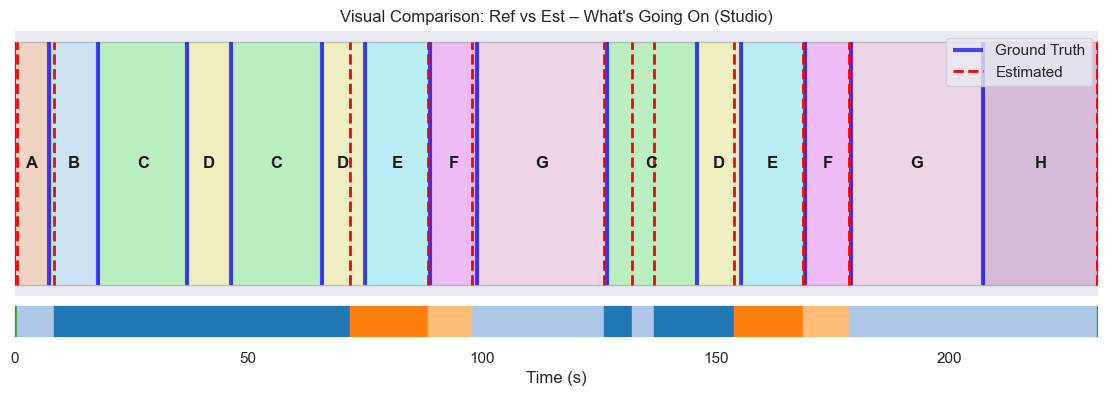

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.500
Recall (R):    0.500
F-measure (F): 0.500


c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


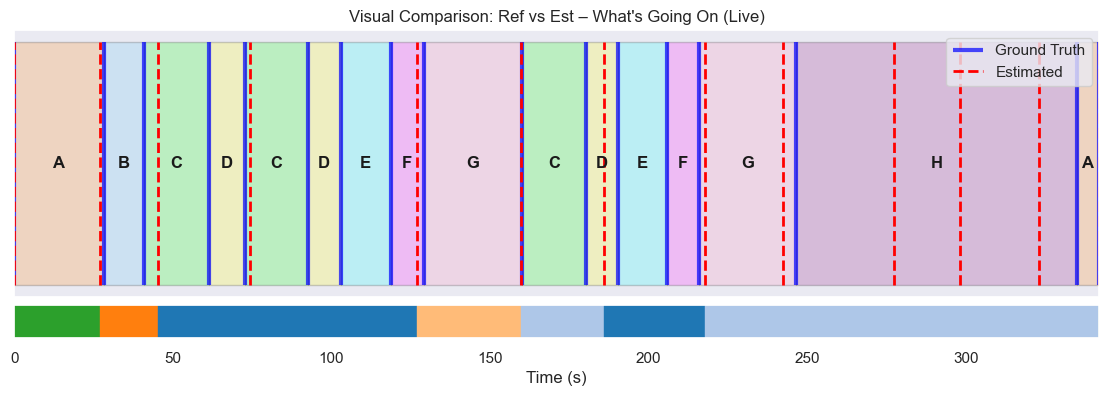

--- Evaluation Results: Whats Going On (Live)
Precision (P): 0.357
Recall (R):    0.333
F-measure (F): 0.345


In [33]:
boundaries, labels = msaf.process("whats_going_on.mp3", feature="pcp",boundaries_id="scluster",labels_id="scluster")
visualiseMSAFGroupingResults(boundaries, labels, ori_segments, "What's Going On (Studio)")
ori_sf_results = evaluateBoundaries(ori_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")


boundaries, labels = msaf.process("whats_going_on_live.mp3", feature="cqt",boundaries_id="sf",labels_id="scluster")
visualiseMSAFGroupingResults(boundaries, labels, liv_segments, "What's Going On (Live)")
liv_sf_results = evaluateBoundaries(liv_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Live)")
print(f"Precision (P): {liv_sf_results[0]:.3f}")
print(f"Recall (R):    {liv_sf_results[1]:.3f}")
print(f"F-measure (F): {liv_sf_results[2]:.3f}")

### **Structural Grouping: CNMF**

The Constrained NMF algorithm works differently to scluster, in the way that it focuses on the individdudal parts of the song instead of the whole, this makes it more robust to key, tempo and timbre changes. This makes it good for analysing noisy, inconsistent tracks such as Live Recordings.

#### **Results**

**Original Track**: Overall a very weak performance from the CNMF algorithm, while it was given the same boundaries as the scluster, it was unable to detect any substantial ammount of repeating structure. The only segment that it seems to have consistently been able to group correctly is the G Section, and unlike the previous algorithm, it was unable to recognise the repeating E, F, G pattern. I expect the poor performance comes from how the different segments evolve over the course of the song, for instance, while segments E+F (the prechoruses) are the same segment, their two appearances in the song vary, with the later appearance including additional harmonies, because CNMF focusses on smaller details such as riffs and chords, it is possible this was the reason it was unable to see the simularity between these segments.

**Live Track**: While only 4 of the 8 distinct segments were correctly identified, it is clear this algorithm managed to extract an abstracted view of the structure, it correclty identifies the crowd noise as its own segment, and from there manages to segment the verse-prechorus-chorus from the postchorus. While it has lost a lot of detail, it is clear that the algorithm was able to extract a general understanding of the song structure from the limited boundaries that it had to work with.

c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


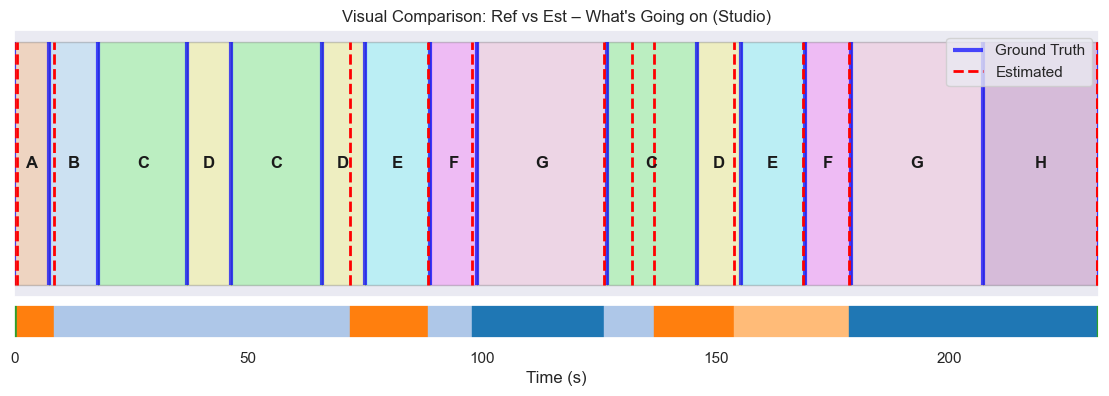

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.500
Recall (R):    0.500
F-measure (F): 0.500


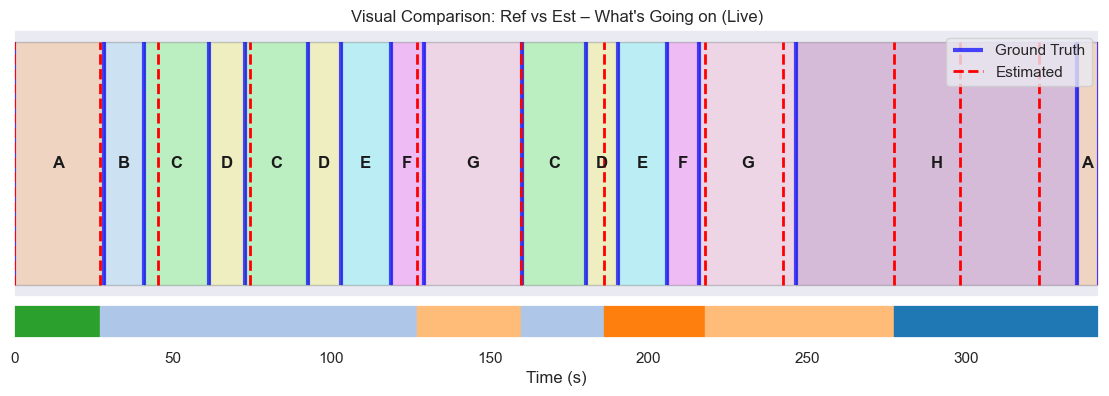

--- Evaluation Results: Whats Going On (Live)
Precision (P): 0.357
Recall (R):    0.333
F-measure (F): 0.345


In [34]:
boundaries, labels = msaf.process("whats_going_on.mp3", feature="pcp",boundaries_id="scluster",labels_id="cnmf")
visualiseMSAFGroupingResults(boundaries, labels, ori_segments, "What's Going on (Studio)")
ori_sf_results = evaluateBoundaries(ori_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")


boundaries, labels = msaf.process("whats_going_on_live.mp3", feature="cqt",boundaries_id="sf",labels_id="cnmf")
visualiseMSAFGroupingResults(boundaries, labels, liv_segments, "What's Going on (Live)")
liv_sf_results = evaluateBoundaries(liv_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Live)")
print(f"Precision (P): {liv_sf_results[0]:.3f}")
print(f"Recall (R):    {liv_sf_results[1]:.3f}")
print(f"F-measure (F): {liv_sf_results[2]:.3f}")

### **Optimisation**

So far in my tests, I have yet to deviate from the preset parameters for each algorithm, now that I know the baseline results for each algorithm on the original and live track, I can now perform a grid search on these parameters in order to optimise the results

I will use a combination of the best performing algorithms for boundary-detection and structural grouping. These are

**Original**: 
- Boundary: **scluster**  
- Structural: **scluster** 

**Live**:
- Boundary: **SF**
- Structural: **CNMF**


c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


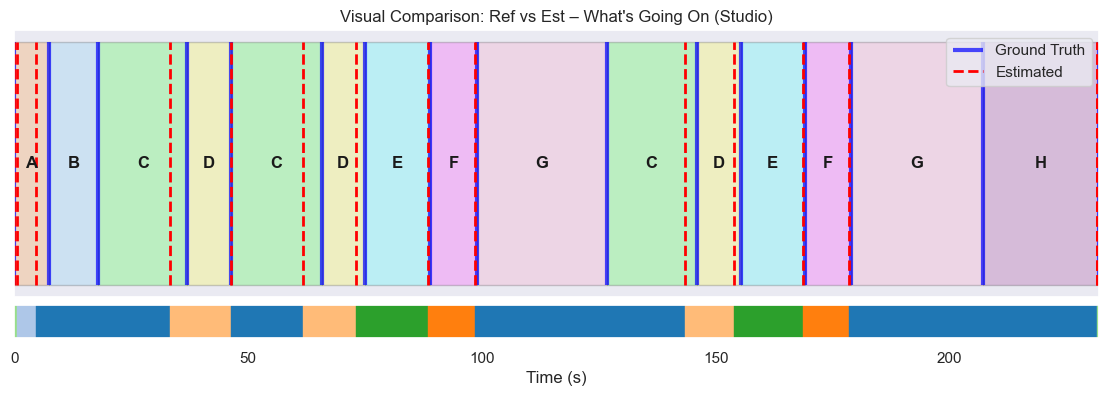

--- Evaluation Results: Whats Going On (Studio)
Precision (P): 0.600
Recall (R):    0.643
F-measure (F): 0.621


In [35]:
config = {
    "num_layers": 4, ##  Decreasing the number of heirarchical layers improves over segmentation
    "scluster_k": 5, ##  Increasing number of spectral clusters that are being searched for allows the algorithm to differenciate between the more 
                     ##  similar sections
    "evec_smooth": 15, ##  Increasing smoothing on the spectral graph helps increase boundary visability
    "rec_smooth": 9,   ##  Increasing or Decreasing smoothing of the recurrance matrix seems to negatively impact results, so ive kept it the same
    "rec_width": 15,   ##  Increasing the rec width suppresses the main diagonal of the ssm, which makes repeating structures more visable
}
boundaries, labels = msaf.process("whats_going_on.mp3", feature="cqt",boundaries_id="scluster",labels_id="scluster", config=config)
visualiseMSAFGroupingResults(boundaries, labels, ori_segments, "What's Going On (Studio)")
ori_sf_results = evaluateBoundaries(ori_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Studio)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")


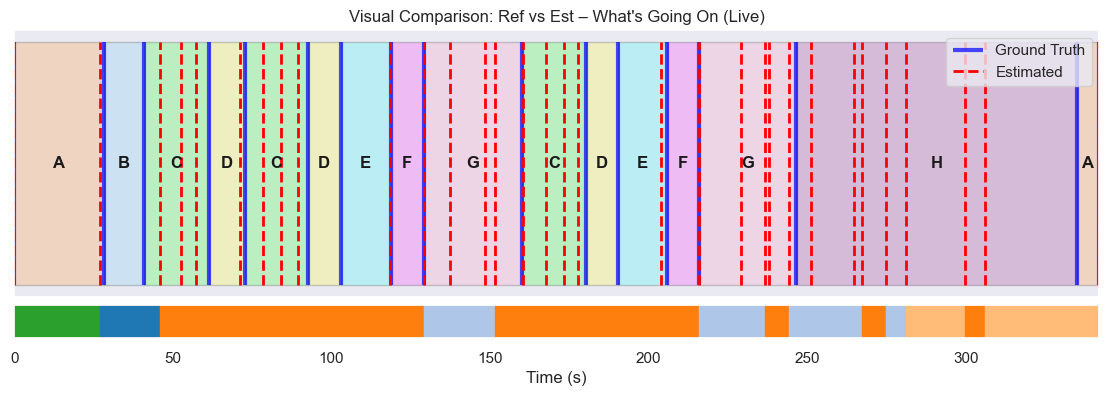

--- Evaluation Results: Whats Going On (Live)
Precision (P): 0.273
Recall (R):    0.600
F-measure (F): 0.375


In [36]:
config = {
    "h": 12,
    "R": 8,
    "rank": 5,
    "R_labels": 6,
    "rank_labels": 4,
    "niters": 400,
    "norm_feats": 2
    # -np.inf, float >= 0, None
}

boundaries, labels = msaf.process("whats_going_on_live.mp3", feature="cqt",boundaries_id="cnmf",labels_id="cnmf", config=config)
visualiseMSAFGroupingResults(boundaries, labels, liv_segments, "What's Going On (Live)")
liv_sf_results = evaluateBoundaries(liv_jam, boundaries, 1)
print(f"--- Evaluation Results: Whats Going On (Live)")
print(f"Precision (P): {liv_sf_results[0]:.3f}")
print(f"Recall (R):    {liv_sf_results[1]:.3f}")
print(f"F-measure (F): {liv_sf_results[2]:.3f}")

#### **Pre-Processing**

**Original Track**

The parameter tweaking worked very well on this track, The algorithm can now differentiate between D, E and F, this is very promising as D and E are quite similar harmonically, so it shows the algorithm is going deeper with its analysis. However it still struggles to differenciate between C, G and H segments , to fix this will require adding pre-processing, my recommendation are:
* Switching from applying a gaussian filter to the spectral graph to a median filter, this will allow differences to still stand out while smoothing out noise, resulting in more subtle differences (in regards to C, G and H) to be found.

**Live Track**

The parameter tweaking for the live track was also moderatally successful, I improved the f-measure by 0.15 and taken the 

## Part 5: Analysis of the AI Song (20 Marks)

### **If I Only Had A Soul (AI Generated)** — Novelty-Based Pipeline Parameters Justification

- **Hop Size = 2048** — consistent resolution across all tracks  
- **feature median smooth length = 71** — smooths overly flat AI chroma patterns  
- **feature downsampling level = 4** — reduces redundancy in repetitive AI harmonies  
- **SSM L Path = 25** — longer paths highlight subtle AI repetitions  
- **SSM Threshold = 0.75** — captures faint structural similarities  
- **SSM Penalty = -0.5** — tolerates ambiguous AI section boundaries  
- **Novelty Kernals = [16, 32]** — enhances weak novelty transitions  
- **Peak Picking Median filter Length = 51** — responsive thresholding for subtle peaks  
- **Peak Picking Novelty Offset = 0.015** — lowers threshold to increase recall  
- **Peak Picking Minimum Prominence = 0.004** — detects very small AI novelty peaks  
- **Peak Picking Minimum Distancemin = 40** — allows closer boundaries in repetitive structure  

### ***AI Gen Novelty-Based Pipeline***

#### **Calculate CQT Chromagram Feature Map**


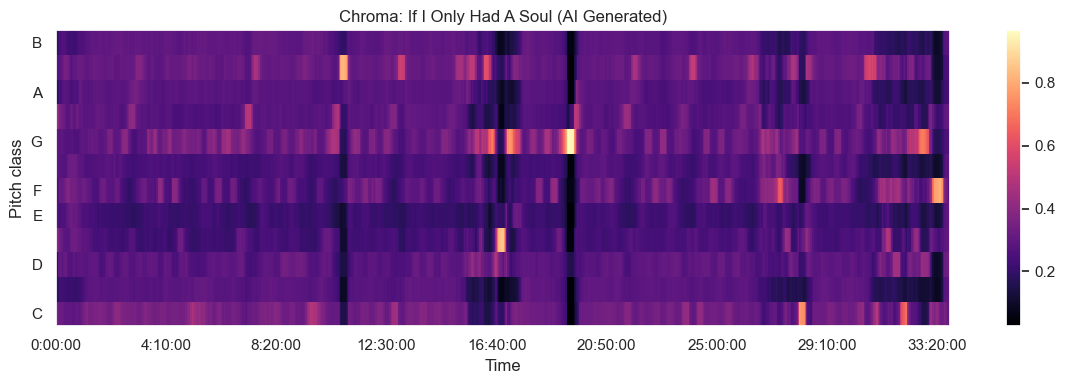

In [37]:

X, Fs_X = calculateProcessedChromagram(gen_y, gen_sr, 2048, 71, 4)

plt.figure(figsize=(12, 4))

librosa.display.specshow(
    X,
    x_axis='time',
    y_axis='chroma',
    sr=Fs_X,
    cmap='magma'
)

plt.colorbar()
plt.title("Chroma: If I Only Had A Soul (AI Generated)")
plt.tight_layout()
plt.show()


#### **Calculate Optimised SSM from CQT Feature**

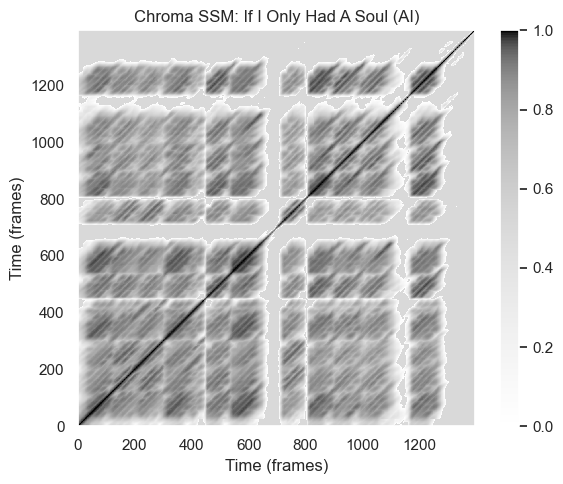

In [38]:
S = calculateOptimisedSSM(X, 25, 0.75, 0.5)

plt.figure(figsize=(6, 5))

libfmp.c4.subplot_matrix_colorbar(
    S,
    plt.gcf(),
    plt.gca(),
    clim=[0, 1],
    title='Chroma SSM: If I Only Had A Soul (AI)',
    xlabel='Time (frames)',
    ylabel='Time (frames)'
)

plt.tight_layout()
plt.show()


Notable Features of the SSM For the AI Generated Track

* Multiple dark blocks along the main diagonal, representing areas of block simulatity (possible segments)
* Small, completely blank space along the edges of the SSM, these represent the silence at the start and end of the recording and tell us no other part of the recording is silent
* Black diagonal lines can be seen running horizontal to the main diagonal, these represent areas of simularity in different parts of the track, the ammount and frequency of these black lines shows the song has very little harmonic variation
* A thick blank segment running down the middle of the SSM, this occurs when the instruments in the track drop out for a stripped back repeat of the verse. This section being blank tells us that it has no simularity to any other section of the song
* A checkered pattern of white lines accross the entire SSM, these represent the segment boundaries of the track

By comparing the SSM produced by the AI recording to the ones produced by the original and live recordings, you can see several key differences
* The AI SSM has a higher frequency of dark areas, these show that the AI song has much less harmonic variation and higher internal repetition than the non-AI tracks.
* The AI SSM has more discrete section boundaries, making it possible to see where the boundaries are just by looking at the SSM.
* There is uniform texture within each block, signifying that each segment has a high level of internal repetition

#### **Calculate Processed Novelty Curve**

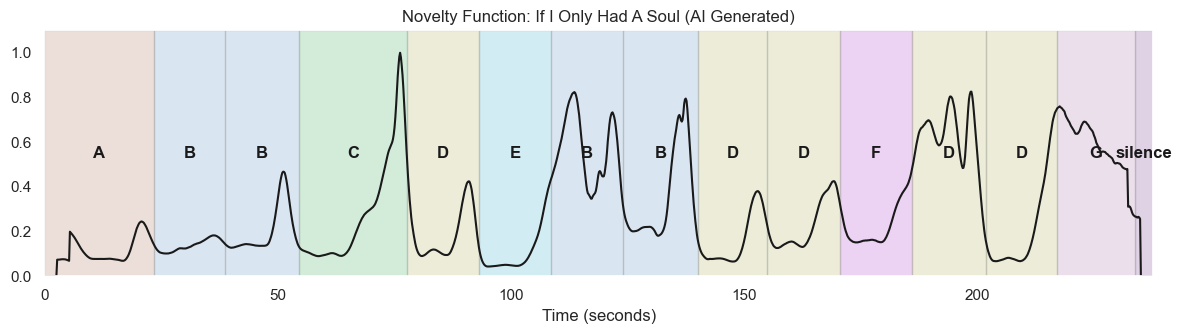

In [39]:
nov = calculateNoveltyCurve(S, [16, 32])

plt.figure(figsize=(12, 3.5))

libfmp.b.plot_signal(nov, Fs=Fs_X, ax=plt.gca(), color='k')
libfmp.b.plot_segments_overlay(gen_segments, ax=plt.gca(), alpha=0.1, edgecolor='k')

plt.title("Novelty Function: If I Only Had A Soul (AI Generated)")
plt.tight_layout()
plt.show()


#### **Detect Peaks Using Adaptive Peak Picking Algorithm**

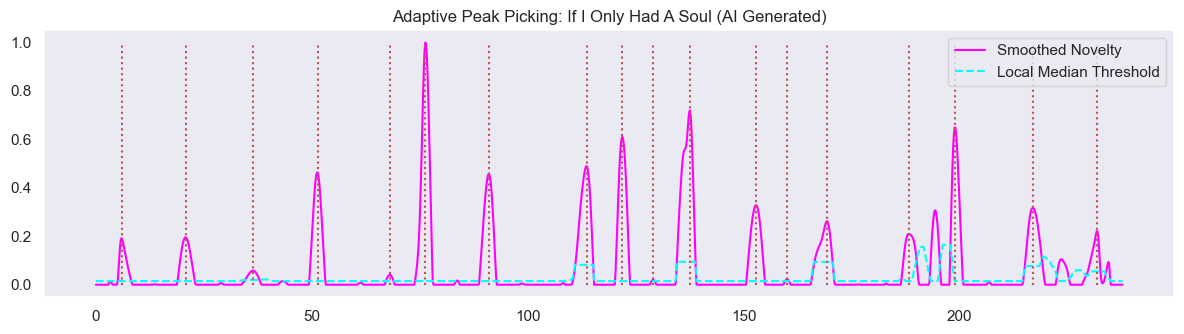

In [40]:
norm_nov, local_threshold, peaks = calculateNoveltyPeaks(nov, median_len=51, offset_factor=0.015, min_prom=0.004,min_dist=40)

time_axis = np.arange(len(nov)) / Fs_X

plt.figure(figsize=(12, 3.5))

# Smoothed novelty curve
plt.plot(time_axis, norm_nov, color='magenta', label='Smoothed Novelty')

# Local median threshold
plt.plot(time_axis, local_threshold, color='cyan', linestyle='--', label='Local Median Threshold')

# Detected peaks
plt.vlines(
    peaks / Fs_X,
    ymin=0,
    ymax=max(nov),
    color='r',
    linestyle=':'
)

plt.title("Adaptive Peak Picking: If I Only Had A Soul (AI Generated)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


#### **Displaying Results**

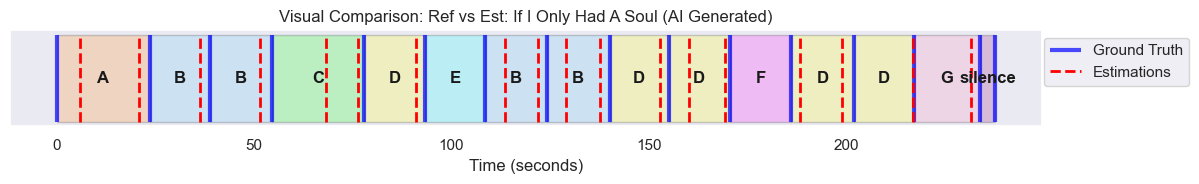

--- Evaluation Results: If I Only Had A Soul (AI Generated)
Precision (P): 0.611
Recall (R):    0.786
F-measure (F): 0.688


In [41]:
compareBoundariesWithGT(gen_segments, peaks, Fs_X, "If I Only Had A Soul (AI Generated)")
eval = evaluateBoundaries(gen_jam, peaks, Fs_X)
print(f"--- Evaluation Results: If I Only Had A Soul (AI Generated)")
print(f"Precision (P): {eval[0]:.3f}")
print(f"Recall (R):    {eval[1]:.3f}")
print(f"F-measure (F): {eval[2]:.3f}")

#### ***Pipeline Results on the AI Track***

Overall I will say the pipeline showed a moderate-high performance level on the AI track (after parameter tweaking)

With an F-Measure of 0.688, it is quantitively on the high end of the boundary algorithms I have come across, however looking at the graph above you can see that while over 60% of all boundaries detected are correct, the majority of the boundaries detected are slightly off, with only one or two boundaries actually hitting the mark. This is possibly due to the high internal repetition present in the song, which when dealing with a recording with such little variation, can make it difficult for the algorithm to detect actual, substantial boundaries. The Precision to Recall ratio tell us that the pipeline Over-Segmented, which for reasons stated previously in this analysis, is purposeful.

### ***AI MSAF Algorithms***

c:\Users\Louis Selwood\anaconda3\envs\comp346\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


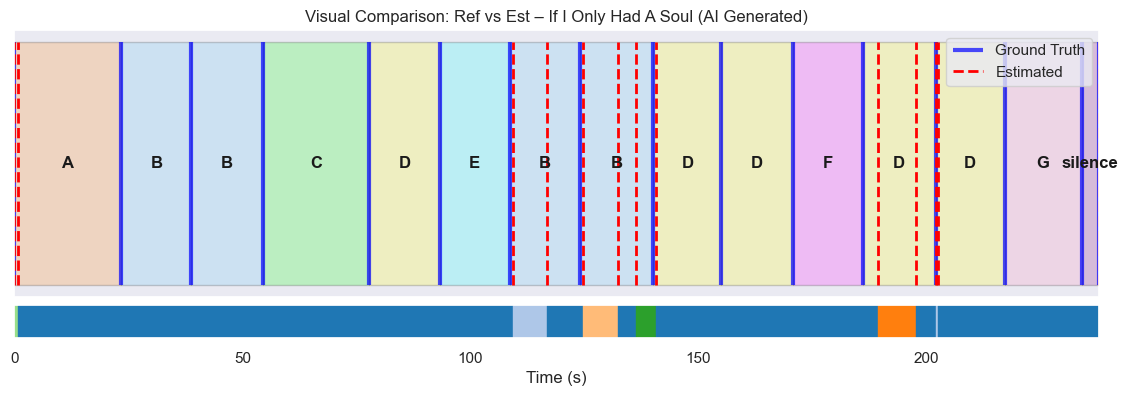

--- Evaluation Results: If I Only Had A Soul (AI Generated)
Precision (P): 0.286
Recall (R):    0.286
F-measure (F): 0.286


In [42]:
config = {
    "num_layers": 6,      # keep → still needed for early boundaries
    "scluster_k": 5,      # keep → grouping is working well
    "evec_smooth": 2,     # ↑ from 3 → softens jitter without killing recall
    "rec_smooth": 9,     # ↑ from 8 → reduces tiny false transitions
    "rec_width": 12       # ↑ from 12 → slightly more diagonal suppression
}



boundaries, labels = msaf.process("if_i_only_had_a_soul.mp3", feature="cqt",boundaries_id="scluster",labels_id="scluster", config=config)
visualiseMSAFGroupingResults(boundaries, labels, gen_segments, "If I Only Had A Soul (AI Generated)")
ori_sf_results = evaluateBoundaries(gen_jam, boundaries, 1)
print(f"--- Evaluation Results: If I Only Had A Soul (AI Generated)")
print(f"Precision (P): {ori_sf_results[0]:.3f}")
print(f"Recall (R):    {ori_sf_results[1]:.3f}")
print(f"F-measure (F): {ori_sf_results[2]:.3f}")

As you can see above, the spectral clustering algorithm did not perform well on the AI track, fine tuning the parameters was very difficult as the parameters for the algorithm are very sensitive due to the inner repetition of the track. I found that tweaking one parameter by a single unit could lead to the algorithm going from extreme under-segmenting to extreme over-segmenting. It especially struggled with the first half of the song, with the algorith either finding no boundaries or finding dozens of false boundaries.


### ***Structural Features***

The AI song follows a fairly standard structure for soul, featuring
* An Intro which sits on the rhythm or "groove" of the song
* A verse with semi-stripped back instrumentation
* A prechorus that switches rhythm slightly to build up to the chorus
* A chorus with a catchy, repeating melody
* A stripped back repetition of a chorus towards the end of the song

All of these things are consistently present in soul, especially pop-soul with motown influences.



### ***Generative AI Statement***

#### **Scope of Use**

I used generative AI in my analysis mainly as a research tool to find techniques which could aid in avoiding under/over segmentation and improving the pipelines performance. Near the beginning of the project I attempted to use it as a way to fine tune the pre-processing parameters but found that AIs general lack of understanding of graphs and what they signified led to it only being able to identify whether the algorithm was over-segmenting or under-segmenting, so instead I decided to opt for a grid search method for parameter tweaking which yielded much greater results.

As this was my first time using the plt library, I also found AI helpful in working through initital errors and misunderstandings. However all the actual code was written by me, as I find if you let Generative AI write actual code (instead of simply aiding you), the code it produces is massively over-complicated.